# Does a 25% subset improve pruning accuracy?

New results for 25% subsets on ResNet-32. [Compare three training seeds at 90% sparsity](#seed-replication) · [Compare 98% sparsity with 80%, 90%, and 95%](#sparsity-98).

[Compare VGG-19 and ResNet-32 at 90% sparsity (Section 12)](#vgg-resnet-comparison).

**Sparsity comparisons at a fixed 25% subset size.** [80%, 90%, and 95% overview](#sparsity-95) · [Detailed 80% versus 90% comparison](#sparsity-comparison). The earlier sections compare subset sizes or examine predictions at 90% sparsity.

ResNet-32 on CIFAR-10 · seed 0 · 90% weight sparsity · 200 final training epochs

The 20% sweep selected 9,000 training images for mask discovery. The 25% sweep selected 11,250. Every sparse model then trained on the same 45,000-image training split. Accuracy below is measured at epoch 200 on the same 5,000 validation images. Each image accounts for 0.02 percentage points.

**On this seed**, the 25% sweep averaged 90.56% across matched configurations, compared with 90.47% at 20%. The best individual result came from 20% loss-mixed selection with eight-round IMP (91.46%). The baseline is the unpruned ResNet-32 trained on all 45,000 training images for 200 epochs at seed 0. It correctly classified 4,703 of 5,000 validation images (94.06%). Both sweeps use this same checkpoint.

The figures and tables are saved in the notebook. To rerun them, open the notebook from the project folder in a Python kernel with pandas, NumPy, IPython, Matplotlib, and SciPy. Both result folders must be present.

In [1]:
%matplotlib inline
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
from IPython.display import display

project = Path.cwd()
sweep_dirs = {
    20: project / "runs/sweeps/079bef776a0f47a580c6",
    25: project / "runs/resnet32-s0-sub25-s90/sweeps/e138bdd3b6e5901d553d",
}
baseline_path = project / "runs/baselines/resnet32-s0-f22257622eb6b83d0d9f/dense-validation.json"
dense = json.loads(baseline_path.read_text(encoding="utf-8"))["metrics"]
names = {
    "random": "Random", "feature_cluster": "Feature clustering", "gradient_cluster": "Gradient clustering",
    "loss": "Loss", "average_margin": "Average margin", "el2n": "EL2N",
    "gradient_norm": "Gradient norm", "forgetting": "Forgetting",
}
pruners = {"magnitude": "Magnitude", "imp": "IMP", "snip": "SNIP", "grasp": "GraSP"}
methods = list(pruners.values())
selector_order = [
    label if selection == "" else f"{label} · {selection}"
    for key, label in names.items()
    for selection in ([""] if key in ("random", "feature_cluster", "gradient_cluster") else ["easy", "hard", "mixed"])
]

frames, wall_seconds = [], {}
for size, folder in sweep_dirs.items():
    frame = pd.read_csv(folder / "runs.csv")
    execution = json.loads((folder / "execution.json").read_text(encoding="utf-8"))
    assert len(frame) == frame["run"].nunique() == len(execution["runs"]) == 77
    assert set(frame["run"]) == {event["run"] for event in execution["runs"]}
    assert frame["fraction"].dropna().eq(size / 100).all()
    assert frame["architecture"].eq("resnet32").all() and frame["seed"].eq(0).all()
    assert frame["final_epochs"].eq(200).all() and frame["partition"].eq("validation").all()
    assert frame["target_sparsity"].eq(0.90).all()
    wall_seconds[size] = execution["wall_seconds"]
    frames.append(frame.assign(size=size))

all_runs = pd.concat(frames, ignore_index=True)
# Express accuracy as integer counts before subtraction so a true tie stays a tie.
all_runs["correct"] = (all_runs["accuracy"] * 5000).round().astype(int)
assert np.allclose(all_runs["correct"], all_runs["accuracy"] * 5000)
all_runs["pruning"] = all_runs["pruner"].map({**pruners, "synflow": "SynFlow"})
subset = all_runs.loc[all_runs["fraction"].notna()].copy()
subset["selection"] = subset["selector"].map(names)
scored = subset["difficulty"].notna()
subset.loc[scored, "selection"] += " · " + subset.loc[scored, "difficulty"]

paired = subset.pivot(index=["selection", "pruning"], columns="size", values="correct")
expected = pd.MultiIndex.from_product([selector_order, methods], names=["selection", "pruning"])
assert paired.index.is_unique and set(paired.index) == set(expected)
paired = paired.reindex(expected)
assert paired[[20, 25]].notna().all().all()
paired["delta"] = paired[25] - paired[20]
pct = paired / 50  # Divide correct-prediction counts by 50 to get percent or percentage points.
dense_pct = 100 * dense["accuracy"]

## 1. Average validation accuracy by pruning method

Each pruning method gets equal weight for each of the 18 selection variants, including random sampling. The last three columns count matched variants where the 25% sweep finished higher, tied, or lower. SynFlow has no subset and appears with the controls.

In [2]:
def summarize_pruner(group):
    change = group["delta"]
    return {
        "20% accuracy (%)": group[20].mean(), "25% accuracy (%)": group[25].mean(),
        "Change (pp)": change.mean(), "25% higher": int((change > 0).sum()),
        "Tied": int((change == 0).sum()), "25% lower": int((change < 0).sum()),
    }

summary = {method: summarize_pruner(pct.xs(method, level="pruning")) for method in methods}
summary["All 72 pairs"] = summarize_pruner(pct)
summary = pd.DataFrame.from_dict(summary, orient="index")
display(summary.style.format({"20% accuracy (%)": "{:.2f}", "25% accuracy (%)": "{:.2f}", "Change (pp)": "{:+.3f}"}))

,20% accuracy (%),25% accuracy (%),Change (pp),25% higher,Tied,25% lower
Magnitude,90.34,90.55,+0.210,10,1,7
IMP,90.73,90.73,+0.003,12,0,6
SNIP,90.21,90.42,+0.212,11,0,7
GraSP,90.62,90.55,-0.067,10,0,8
All 72 pairs,90.47,90.56,+0.090,43,1,28


## 2. All selection and pruning combinations

Both panels use the same color scale. Compare the same row and column across panels to see how that configuration changed. Darker cells have higher validation accuracy. The bottom row shows the full-data pruning control for each column. Compare a subset with the bottom cell in the same column and panel to hold the pruner and GPU fixed.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


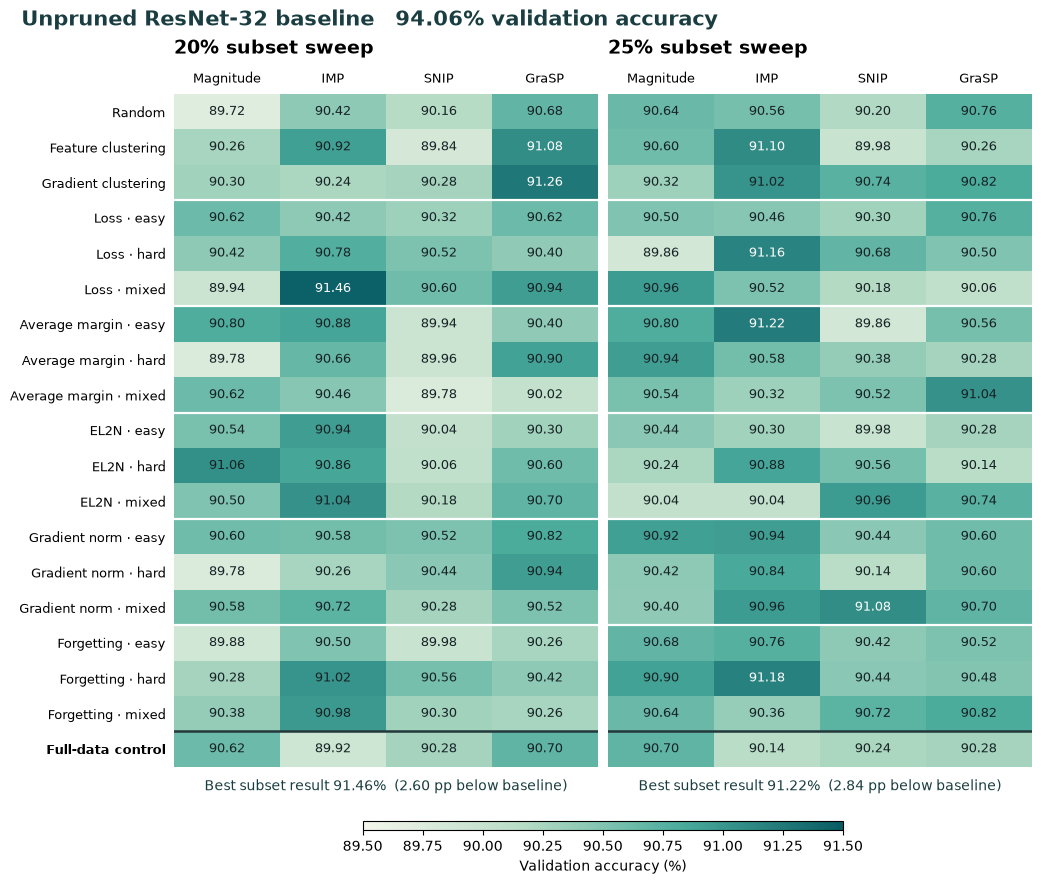

In [3]:
full_counts = all_runs.loc[all_runs["selector"].eq("full")].pivot(
    index="pruning", columns="size", values="correct"
).reindex(methods)
assert full_counts.shape == (4, 2) and full_counts.notna().all().all()
full_counts["delta"] = full_counts[25] - full_counts[20]

def matrix(column):
    values = pct[column].unstack("pruning").reindex(index=selector_order, columns=methods)
    label = "Full-data repeat" if column == "delta" else "Full-data control"
    values.loc[label] = full_counts[column] / 50
    return values

def draw_grid(ax, values, cmap, lower, upper, signed=False, show_labels=True):
    data = values.to_numpy()
    image = ax.imshow(data, vmin=lower, vmax=upper, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(methods)), labels=methods)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(values)), labels=values.index if show_labels else [])
    if show_labels:
        ax.get_yticklabels()[-1].set_fontweight("bold")
    ax.tick_params(length=0, pad=6, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for (row, col), value in np.ndenumerate(data):
        red, green, blue, _ = image.cmap(image.norm(value))
        luminance = .2126 * red + .7152 * green + .0722 * blue
        label = f"{value:+.2f}" if signed and value else f"{value:.2f}"
        ax.text(col, row, label, ha="center", va="center", fontsize=9,
                color="white" if luminance < .48 else "#172326")
    for end in [2, 5, 8, 11, 14]:
        ax.axhline(end + .5, color="white", linewidth=1.6)
    ax.axhline(len(values) - 1.5, color="#23383b", linewidth=1.8)
    return image

teal = LinearSegmentedColormap.from_list("accuracy", ["#f4f6eb", "#b7dcc5", "#4aab9c", "#095c64"])
lower = np.floor(pct[[20, 25]].min().min() * 2) / 2
upper = np.ceil(pct[[20, 25]].max().max() * 2) / 2
fig, axes = plt.subplots(1, 2, figsize=(10.3, 8.7), layout="constrained")
fig.suptitle(f"Unpruned ResNet-32 baseline   {dense_pct:.2f}% validation accuracy",
             x=.015, ha="left", fontsize=15, fontweight="semibold", color="#193d40")
for ax, size in zip(axes, [20, 25]):
    image = draw_grid(ax, matrix(size), teal, lower, upper, show_labels=size == 20)
    ax.set_title(f"{size}% subset sweep", loc="left", fontsize=14, fontweight="semibold", pad=13)
    best_sparse = pct[size].max()
    gap = dense_pct - best_sparse
    ax.set_xlabel(f"Best subset result {best_sparse:.2f}%  ({gap:.2f} pp below baseline)",
                  fontsize=10, labelpad=9, color="#193d40")
bar = fig.colorbar(image, ax=axes, location="bottom", shrink=.56, aspect=50, pad=.035)
bar.set_label("Validation accuracy (%)")
plt.show()

### Easy, hard and mixed selection

Each scoring rule ranks training images **within each class**. Easy takes the lowest hardness scores, hard takes the highest, and mixed fills half the quota from each end (one extra hard image for an odd quota). Five selectors support these choices: loss, average margin, EL2N, gradient norm, and forgetting.

The first figure averages the five selectors within each pruner. The last row averages all 20 selector–pruner pairs per difficulty and subset size. Each gray tick marks the matching full-data pruning control, averaged across pruners on the last row. All values are seed-0 validation accuracies.

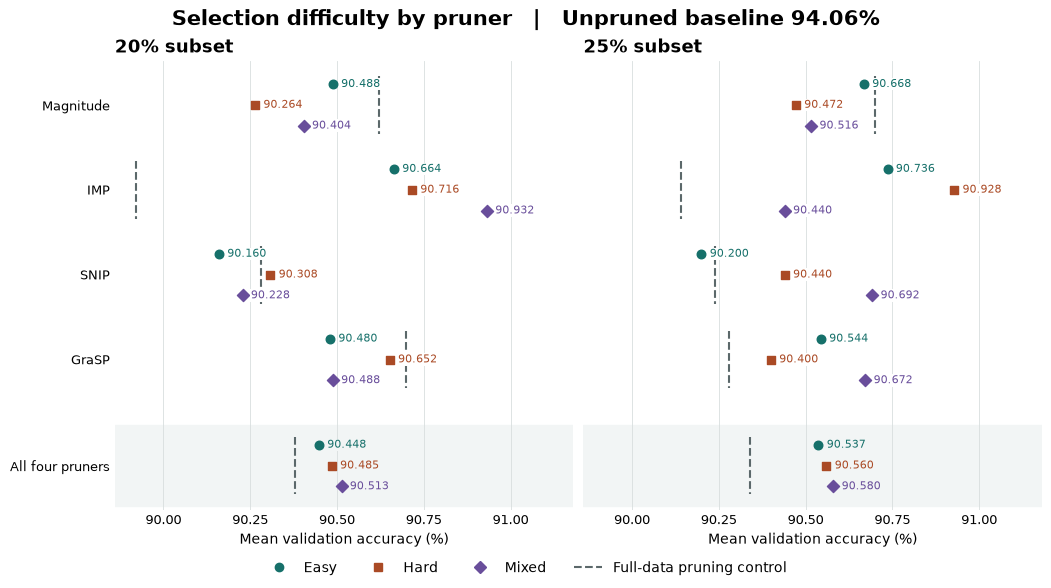

In [4]:
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

difficulty_order = ["easy", "hard", "mixed"]
scoring_keys = ["loss", "average_margin", "el2n", "gradient_norm", "forgetting"]
difficulty_runs = subset.loc[subset["difficulty"].isin(difficulty_order)]
difficulty_counts = difficulty_runs.pivot(
    index=["size", "pruning", "selector"], columns="difficulty", values="correct"
)
expected_groups = pd.MultiIndex.from_product(
    [[20, 25], methods, scoring_keys], names=["size", "pruning", "selector"]
)
assert difficulty_counts.index.is_unique and set(difficulty_counts.index) == set(expected_groups)
difficulty_accuracy = difficulty_counts.reindex(index=expected_groups, columns=difficulty_order) / 50
assert difficulty_accuracy.shape == (40, 3) and difficulty_accuracy.notna().all().all()

pruner_means = difficulty_accuracy.groupby(level=["size", "pruning"]).mean()
overall_means = difficulty_accuracy.groupby(level="size").mean()
full_pool = all_runs.loc[all_runs["selector"].eq("full")].pivot(
    index="pruning", columns="size", values="correct"
).reindex(methods) / 50
assert full_pool.notna().all().all()

styles = {"easy": ("#16706a", "o"), "hard": ("#aa4a25", "s"), "mixed": ("#694e9b", "D")}
rows = [*methods, "All four pruners"]
y = np.array([0, 1, 2, 3, 4.25])
lowest = min(pruner_means.min().min(), full_pool.min().min())
highest = max(pruner_means.max().max(), full_pool.max().max())
fig, axes = plt.subplots(1, 2, figsize=(10.4, 5.8), sharex=True, sharey=True, layout="constrained")
for ax, size in zip(axes, [20, 25]):
    means = pruner_means.loc[size].reindex(methods)
    means.loc[rows[-1]] = overall_means.loc[size]
    reference = full_pool[size].tolist() + [full_pool[size].mean()]
    ax.axhspan(y[-1] - .48, y[-1] + .48, color="#f2f5f5", zorder=0)
    ax.grid(axis="x", linewidth=.6, color="#d8dede", zorder=0)
    ax.vlines(reference, y - .34, y + .34, color="#5b686a", linewidth=1.5, linestyle="--", zorder=2)
    for level, offset in zip(difficulty_order, [-.245, 0, .245]):
        color, marker = styles[level]
        values = means[level].to_numpy()
        ax.scatter(values, y + offset, s=38, marker=marker, color=color, zorder=3)
        for x, yy in zip(values, y + offset):
            ax.annotate(f"{x:.3f}", (x, yy), xytext=(6, 0), textcoords="offset points",
                        va="center", fontsize=8, color=color, zorder=4,
                        bbox=dict(facecolor="#f2f5f5" if yy > y[-1] - .5 else "white",
                                  edgecolor="none", pad=.5))
    ax.set_title(f"{size}% subset", loc="left", fontsize=13, weight="bold")
    ax.set_xlabel("Mean validation accuracy (%)")
    ax.set_yticks(y, rows)
    ax.set_ylim(y[-1] + .52, -.52)
    ax.set_xlim(np.floor(lowest * 10) / 10 - .04, np.ceil(highest * 10) / 10 + .18)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.tick_params(axis="both", length=0, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
handles = [Line2D([], [], marker=styles[level][1], color=styles[level][0], linestyle="none",
                  label=level.title()) for level in difficulty_order]
handles.append(Line2D([], [], color="#5b686a", linestyle="--", label="Full-data pruning control"))
fig.legend(handles=handles, loc="outside lower center", ncols=4, frameon=False)
fig.suptitle(f"Selection difficulty by pruner   |   Unpruned baseline {dense_pct:.2f}%",
             fontsize=15, weight="bold")
plt.show()

#### How difficulty interacts with the scoring rule

Each panel holds the pruner and subset size fixed. Read across a row to compare easy, hard and mixed selections using the same scoring rule. Each cell shows one run; all eight panels share a color scale.

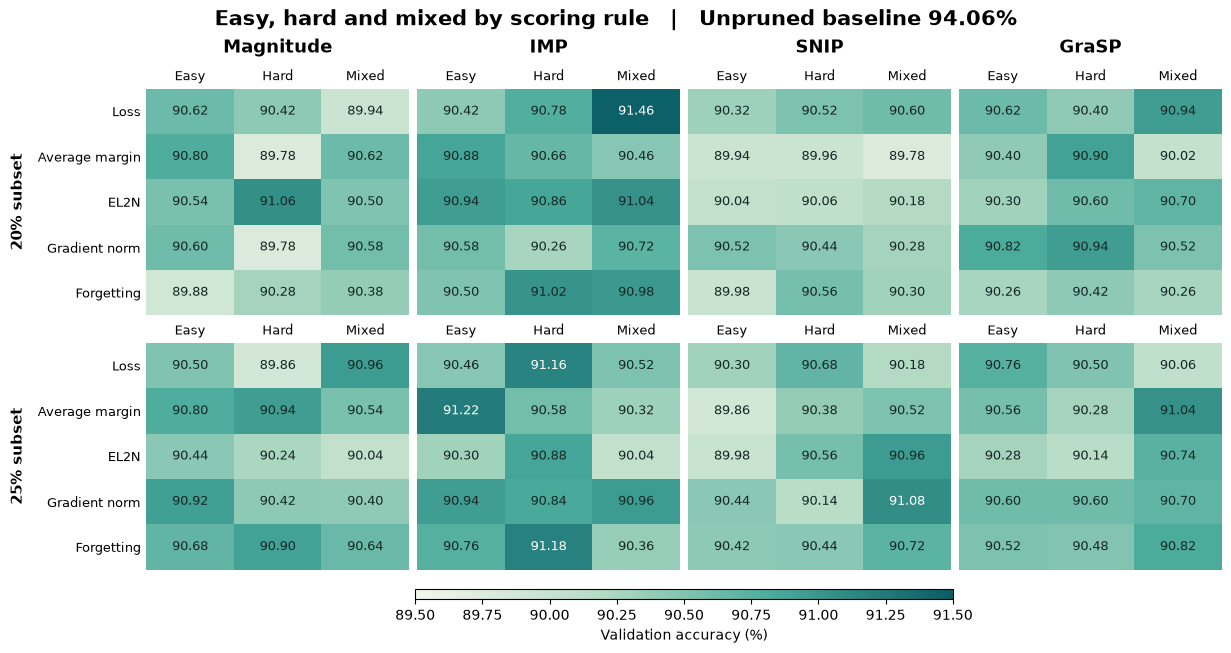

In [5]:
values = difficulty_accuracy.to_numpy()
lower_bound = np.floor(values.min() * 2) / 2
upper_bound = np.ceil(values.max() * 2) / 2
difficulty_cmap = LinearSegmentedColormap.from_list(
    "difficulty_accuracy", ["#f4f6eb", "#b7dcc5", "#4aab9c", "#095c64"]
)
fig, panels = plt.subplots(2, 4, figsize=(12.2, 6.4), layout="constrained")
for row, size in enumerate([20, 25]):
    for col, pruner in enumerate(methods):
        ax = panels[row, col]
        grid = difficulty_accuracy.xs((size, pruner), level=("size", "pruning")).reindex(scoring_keys)
        image = ax.imshow(grid, cmap=difficulty_cmap, vmin=lower_bound, vmax=upper_bound, aspect="auto")
        ax.set_xticks(range(3), [s.title() for s in difficulty_order])
        ax.xaxis.tick_top()
        ax.set_yticks(range(5), [names[s] for s in scoring_keys] if col == 0 else [])
        ax.tick_params(length=0, labelsize=9, pad=4)
        if row == 0:
            ax.set_title(pruner, fontsize=13, weight="bold", pad=12)
        if col == 0:
            ax.set_ylabel(f"{size}% subset", fontsize=11, weight="bold", labelpad=9)
        for (i, j), accuracy in np.ndenumerate(grid.to_numpy()):
            r, g, b, _ = image.cmap(image.norm(accuracy))
            brightness = .2126*r + .7152*g + .0722*b
            ax.text(j, i, f"{accuracy:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if brightness < .48 else "#162926")
        for spine in ax.spines.values():
            spine.set_visible(False)
bar = fig.colorbar(image, ax=panels, location="bottom", shrink=.50, aspect=52, pad=.035)
bar.set_label("Validation accuracy (%)")
fig.suptitle(f"Easy, hard and mixed by scoring rule   |   Unpruned baseline {dense_pct:.2f}%",
             fontsize=15, weight="bold")
plt.show()

Mixed selection had the highest overall mean at both sizes, ahead of easy by 0.065 percentage points at 20% and 0.043 points at 25%. The ordering differed by pruner. For IMP, mixed led at 20% (90.932%), while hard led at 25% (90.928%). Each configuration has one seed, so these rankings describe the two sweeps.

## 3. Which combinations gained or lost accuracy?

Each cell is the 25% result minus the 20% result in percentage points. The largest gain was hard average-margin selection with magnitude pruning (+1.16 pp). The largest drop was mixed EL2N selection with IMP (−1.00 pp). The full-data repeat row shows how much the same control differed between machines. Both control runs used the full training pool.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


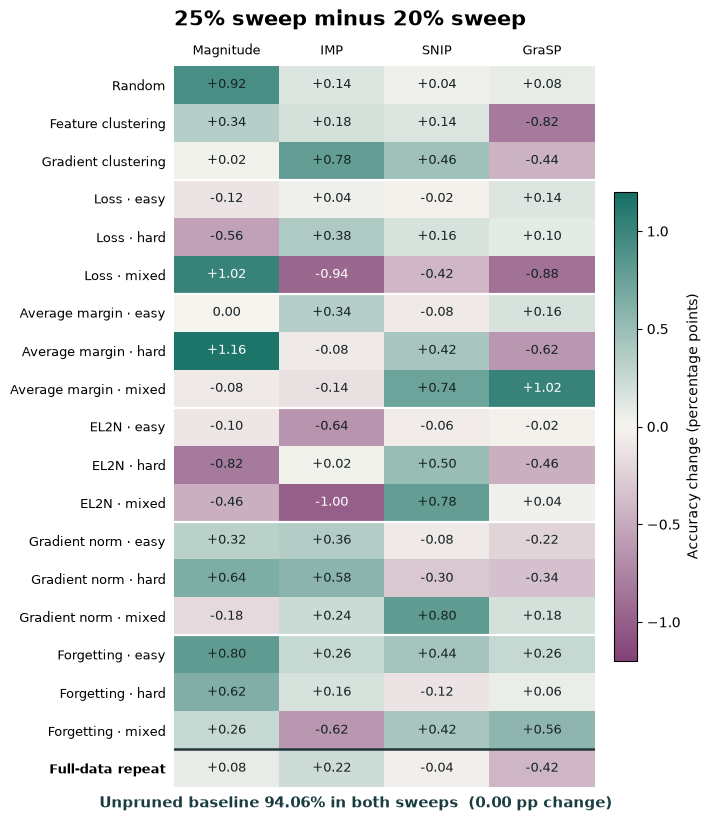

In [6]:
diverging = LinearSegmentedColormap.from_list("change", ["#824276", "#f7f5f0", "#167065"])
limit = np.ceil(pct["delta"].abs().max() * 10) / 10
fig, ax = plt.subplots(figsize=(7.0, 8.1), layout="constrained")
image = draw_grid(ax, matrix("delta"), diverging, -limit, limit, signed=True)
ax.set_title("25% sweep minus 20% sweep", loc="left", fontsize=15, fontweight="semibold", pad=13)
bar = fig.colorbar(image, ax=ax, shrink=.65, pad=.045)
bar.set_label("Accuracy change (percentage points)")
fig.supxlabel(f"Unpruned baseline {dense_pct:.2f}% in both sweeps  (0.00 pp change)",
              fontsize=11, fontweight="semibold", color="#193d40")
plt.show()

## 4. Leading configurations and the random baseline

The first table selects the highest validation accuracy within each pruner and sweep. The gap to random uses the same pruner on the same machine. The second table ranks configurations by the **lower** of their two accuracies. This rewards configurations that performed well at both subset sizes. This ranking uses seed 0 only.

In [7]:
random_accuracy = pct.xs("Random", level="selection")
winners = []
for method in methods:
    candidates = pct.xs(method, level="pruning")
    for size in [20, 25]:
        best = candidates[size].max()
        for selection in candidates.index[candidates[size].eq(best)]:
            winners.append({"Pruner": method, "Subset": f"{size}%", "Best selection": selection,
                            "Best (%)": best, "Random (%)": random_accuracy.loc[method, size],
                            "Gap to random (pp)": best - random_accuracy.loc[method, size]})
display(pd.DataFrame(winners).set_index(["Pruner", "Subset"]).style.format(
    {"Best (%)": "{:.2f}", "Random (%)": "{:.2f}", "Gap to random (pp)": "{:+.2f}"}))

shortlist = pct[[20, 25]].copy()
shortlist["Lower of both (%)"] = shortlist.min(axis=1)
shortlist = shortlist.sort_values("Lower of both (%)", ascending=False).head(5)
display(shortlist.rename(columns={20: "20% accuracy (%)", 25: "25% accuracy (%)"}).style.format("{:.2f}"))

,size,20% accuracy (%),25% accuracy (%),Lower of both (%)
selection,pruning,,,
Forgetting · hard,IMP,91.02,91.18,91.02
Feature clustering,IMP,90.92,91.10,90.92
Average margin · easy,IMP,90.88,91.22,90.88
EL2N · hard,IMP,90.86,90.88,90.86
Gradient clustering,GraSP,91.26,90.82,90.82


## 5. Dense, full-data and data-free controls

The dense reference is the same saved seed-0 model for both sweeps. Each GPU independently ran the four full-data pruning controls and SynFlow. Variation in these control scores shows why the difference between sweeps cannot be attributed entirely to subset size. The full pool contains 45,000 training images. Magnitude and IMP used 70,400 discovery updates for their full-data controls and 14,080 for their subset runs. SNIP and GraSP scored 256 class-balanced images drawn from the designated pool. SynFlow used synthetic input. Every sparse model then trained on all 45,000 training images for 200 epochs.

In [8]:
controls = all_runs.loc[all_runs["fraction"].isna()].pivot(index="pruning", columns="size", values="correct") / 50
controls = controls.reindex([*methods, "SynFlow"])
assert controls.shape == (5, 2) and controls.notna().all().all()
controls.index = [f"{method} (full data)" for method in methods] + ["SynFlow (data-free)"]
controls.loc["Dense baseline"] = [dense_pct, dense_pct]
controls = controls.loc[["Dense baseline", *controls.index[:-1]]].copy()
controls["Difference (pp)"] = controls[25] - controls[20]
display(controls.rename(columns={20: "20% sweep (%)", 25: "25% sweep (%)"}).style.format(
    {"20% sweep (%)": "{:.2f}", "25% sweep (%)": "{:.2f}", "Difference (pp)": "{:+.2f}"}))

size,20% sweep (%),25% sweep (%),Difference (pp)
Dense baseline,94.06,94.06,+0.00
Magnitude (full data),90.62,90.70,+0.08
IMP (full data),89.92,90.14,+0.22
SNIP (full data),90.28,90.24,-0.04
GraSP (full data),90.70,90.28,-0.42
SynFlow (data-free),90.86,90.42,-0.44


## 6. Validation accuracy by class

This table compares the best subset configuration in each sweep with the dense reference. The dense model and both sparse winners were evaluated on the same 500 validation images per class.

In [9]:
best_rows = subset.loc[subset.groupby("size")["correct"].idxmax()].set_index("size")
classes = list(dense["per_class"])
per_class = pd.DataFrame({"Dense (%)": [100 * dense["per_class"][c]["accuracy"] for c in classes]}, index=classes)
for size in [20, 25]:
    best = best_rows.loc[size]
    label = f"{size}% {best['selection']} + {best['pruning']} (%)"
    per_class[label] = [100 * best[c + "_accuracy"] for c in classes]
per_class.index.name = "CIFAR-10 class"
display(per_class.style.format("{:.2f}"))

,Dense (%),20% Loss · mixed + IMP (%),25% Average margin · easy + IMP (%)
CIFAR-10 class,,,
airplane,94.40,91.20,91.20
automobile,97.60,96.00,95.60
bird,93.20,88.00,90.00
cat,89.00,84.20,81.00
deer,94.60,92.40,91.00
dog,89.40,88.60,86.80
frog,95.40,93.60,95.00
horse,94.20,92.20,94.20
ship,95.80,93.40,94.00


## 7. Time and interpretation

Wall time comes from the sweep runner and includes shared work across its 77 runs. GPU model and host differed between sweeps, so these timings describe those two rentals. The validation rankings can guide the choice of configurations to repeat on seeds 1 and 2.

In [10]:
timing = []
for size, group in all_runs.groupby("size"):
    seconds = round(wall_seconds[size])
    hours, remainder = divmod(seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    timing.append({"Subset": f"{size}%", "GPU": group["hardware"].unique().item(),
                   "Discovery pool (images)": int(size * 45000 / 100), "Completed runs": len(group),
                   "Sweep wall time": f"{hours} h {minutes:02d} min {seconds:02d} s"})
display(pd.DataFrame(timing).set_index("Subset"))

,GPU,Discovery pool (images),Completed runs,Sweep wall time
Subset,,,,
20%,NVIDIA GeForce RTX 5080,9000,77,11 h 46 min 30 s
25%,NVIDIA GeForce RTX 5090,11250,77,12 h 10 min 37 s


**What to carry forward.** IMP had the highest mean accuracy at both sizes. Hard forgetting with IMP had the highest lower-of-two accuracy and beat random IMP in both sweeps. Mixed-loss IMP was the best individual 20% run but fell 0.94 pp at 25%. Replicating these configurations across seeds would test whether the differences hold.

**Source reports.** [20% per-run metrics](runs/sweeps/079bef776a0f47a580c6/runs.csv) · [25% per-run metrics](runs/resnet32-s0-sub25-s90/sweeps/e138bdd3b6e5901d553d/runs.csv) · [dense baseline](runs/baselines/resnet32-s0-f22257622eb6b83d0d9f/dense-validation.json)

## 8. Which images did the 25% selectors share?

This section follows the saved image IDs for the **18 subsets in the ResNet-32, seed-0, 25% subset, 90% sparsity sweep**. A subset is selected once and reused by the four data-dependent pruners. The unit of comparison here is a pair of selectors. There are 153 distinct pairs.

**Overlap** is the number of shared IDs divided by 11,250, the size of either subset. **Jaccard similarity** divides the same number by the size of the union. **Images only in A** counts how many selections would change when switching from A to B. Two independent, class-balanced 25% draws have an expected intersection of 2,812.5 images, or **25% overlap**: within each class a new draw includes each image with probability 1,125 / 4,500.

**How to read the tree.** Both axes follow the same average-linkage hierarchical clustering of the saved image sets. The tree uses Jaccard distance (one minus intersection divided by union). Lower joins indicate more similar subsets. Optimal leaf ordering arranges neighboring branches to minimize the sum of adjacent distances. The heatmap shows the original overlap percentages, with the closest pair outlined in gold.

The saved random selector is one particular draw. Random selection, cluster initialization, and tie-breaking reuse per-class seeds in this implementation. Use 25% as an independent-draw reference; a comparison with the saved random subset can differ substantially. [25% subset records](runs/resnet32-s0-sub25-s90/subsets/) · [Training/validation split](runs/resnet32-s0-sub25-s90/splits/cifar10-260.json)

In [11]:
from collections import Counter
from itertools import combinations
import hashlib

report_25 = sweep_dirs[25]
root_25 = report_25.parents[1]
split_25 = json.loads((root_25 / "splits/cifar10-260.json").read_text(encoding="utf-8"))
train_ids_25 = set(split_25["train"])
assert len(train_ids_25) == 45000 and train_ids_25.isdisjoint(split_25["val"])

def saved_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()[:20]

# Follow the actual sweep's references so other run folders cannot enter the comparison.
referenced_subsets = set()
for event in json.loads((report_25 / "execution.json").read_text(encoding="utf-8"))["runs"]:
    record = json.loads((root_25 / "final" / event["run"] / "validation.json").read_text(encoding="utf-8"))
    if record["subset_spec"] is not None:
        referenced_subsets.add(record["pruning"]["subset"])
assert len(referenced_subsets) == 18

selected_ids_25 = {}
split_id_25 = saved_digest(split_25)
for subset_id in sorted(referenced_subsets):
    artifact = json.loads((root_25 / "subsets" / subset_id / "subset.json").read_text(encoding="utf-8"))
    spec = artifact["spec"]
    assert artifact["id"] == subset_id and artifact["split_id"] == split_id_25
    assert artifact["recipe"]["arch"] == "resnet32" and artifact["recipe"]["seed"] == 0
    assert spec["fraction"] == .25 and artifact["ids_digest"] == saved_digest(artifact["ids"])
    ids = set(artifact["ids"])
    assert len(ids) == len(artifact["ids"]) == 11250 and ids <= train_ids_25
    assert artifact["class_counts"] == [1125] * 10
    label = names[spec["method"]]
    if "difficulty" in spec:
        label += " · " + spec["difficulty"]
    assert label not in selected_ids_25
    selected_ids_25[label] = ids
assert set(selected_ids_25) == set(selector_order)
subset_n = len(selected_ids_25["Random"])
chance_pct = 100 * subset_n / len(train_ids_25)

pair_rows = []
shared_pct = pd.DataFrame(100.0, index=selector_order, columns=selector_order)
for left, right in combinations(selector_order, 2):
    a, b = selected_ids_25[left], selected_ids_25[right]
    shared = len(a & b)
    overlap = 100 * shared / subset_n
    shared_pct.loc[left, right] = shared_pct.loc[right, left] = overlap
    pair_rows.append({"Selector A": left, "Selector B": right, "Shared images": shared,
                      "Only A": len(a - b), "Only B": len(b - a), "Overlap (%)": overlap,
                      "Jaccard (%)": 100 * shared / len(a | b), "Above chance (pp)": overlap - chance_pct})
overlap_pairs_25 = (pd.DataFrame(pair_rows).sort_values("Shared images", ascending=False)
                    .reset_index(drop=True))
assert len(overlap_pairs_25) == 153 and np.allclose(shared_pct, shared_pct.T)
assert (overlap_pairs_25["Shared images"] + overlap_pairs_25["Only A"]).eq(subset_n).all()

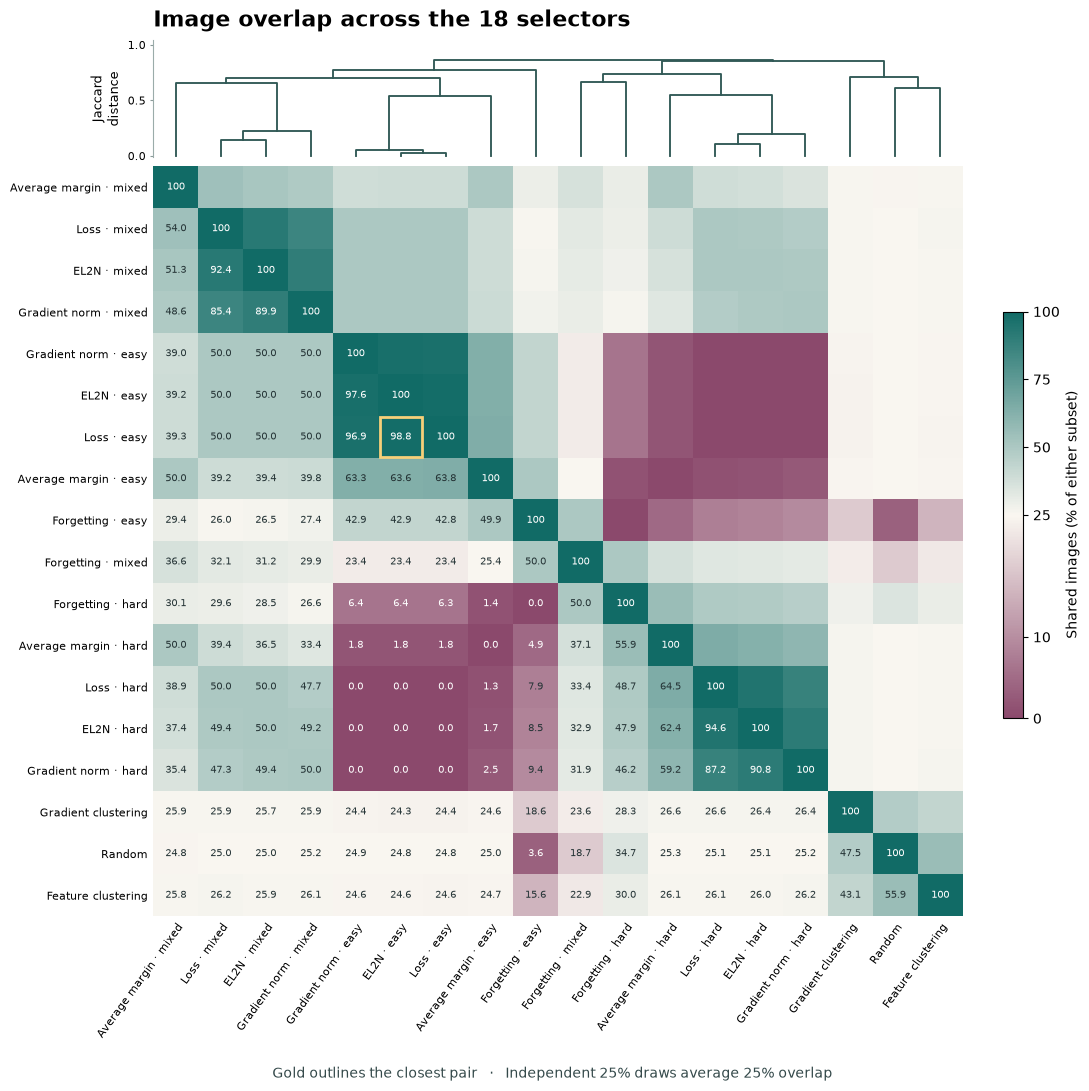

In [12]:
from itertools import combinations
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from scipy.cluster.hierarchy import dendrogram, linkage

# SciPy expects pairwise distances in upper-triangle order for a condensed matrix.
jaccard_distances = []
for left, right in combinations(selector_order, 2):
    a, b = selected_ids_25[left], selected_ids_25[right]
    jaccard_distances.append(1 - len(a & b) / len(a | b))
tree = linkage(jaccard_distances, method="average", optimal_ordering=True)
branches = dendrogram(tree, no_plot=True)
cluster_order = [selector_order[i] for i in branches["leaves"]]
clustered_overlap = shared_pct.loc[cluster_order, cluster_order]
values = clustered_overlap.to_numpy()
n_selectors = len(cluster_order)

colors = LinearSegmentedColormap.from_list("subset_overlap", ["#8b496c", "#faf7f1", "#116b66"])
norm = TwoSlopeNorm(vmin=0, vcenter=chance_pct, vmax=100)
fig = plt.figure(figsize=(11.4, 11.3))
grid = fig.add_gridspec(2, 1, left=.18, right=.89, bottom=.175, top=.95,
                        height_ratios=[1.25, 8], hspace=.02)
tree_ax = fig.add_subplot(grid[0, 0])
ax = fig.add_subplot(grid[1, 0], sharex=tree_ax)
cbar_ax = fig.add_axes([.925, .35, .018, .36])

# Dendrogram leaves use x = 5, 15, 25, ...; heatmap cell centers use x = 0, 1, 2, ...
for xs, heights in zip(branches["icoord"], branches["dcoord"]):
    tree_ax.plot((np.asarray(xs) - 5) / 10, heights, color="#315956", lw=1.35)
tree_ax.set_ylim(-.015, 1.04)
tree_ax.set_yticks([0, .5, 1])
tree_ax.set_ylabel("Jaccard\ndistance", fontsize=9)
tree_ax.tick_params(axis="x", bottom=False, labelbottom=False)
tree_ax.tick_params(axis="y", labelsize=8, length=2, color="#8a9a99")
tree_ax.spines[["top", "right", "bottom"]].set_visible(False)
tree_ax.spines["left"].set_color("#9bacaa")
tree_ax.set_title("Image overlap across the 18 selectors", loc="left", fontsize=16, weight="bold", pad=10)
image = ax.imshow(values, cmap=colors, norm=norm, aspect="auto", interpolation="nearest")
ticks = np.arange(n_selectors)
ax.set_yticks(ticks, cluster_order)
ax.set_xticks(ticks, cluster_order, rotation=54, ha="right", rotation_mode="anchor")
ax.set_xlim(-.5, n_selectors - .5)
ax.tick_params(length=0, labelsize=8, pad=4)
for spine in ax.spines.values():
    spine.set_visible(False)
for row, col in zip(*np.tril_indices(n_selectors)):
    v = values[row, col]
    r, g, b, _ = colors(norm(v))
    color = "white" if .2126*r + .7152*g + .0722*b < .51 else "#253436"
    ax.text(col, row, f"{v:.1f}" if row != col else "100", ha="center", va="center",
            color=color, fontsize=7.0)
closest = overlap_pairs_25.iloc[0]
i, j = sorted((cluster_order.index(closest["Selector A"]), cluster_order.index(closest["Selector B"])))
ax.add_patch(Rectangle((i - .47, j - .47), .94, .94, fill=False, edgecolor="#f7d079", lw=2.0))
bar = fig.colorbar(image, cax=cbar_ax, ticks=[0, 10, 25, 50, 75, 100])
bar.set_label("Shared images (% of either subset)")
fig.text(.53, .032, f"Gold outlines the closest pair   ·   Independent 25% draws average {chance_pct:.0f}% overlap",
         ha="center", fontsize=10, color="#34494a")
plt.show()

#### Pairs worth inspecting

Loss and EL2N easy selection differ by just 139 images on each side. Easy average margin and hard forgetting have only 158 IDs in common, even though both scored above 91% with IMP. For a single scoring rule, easy and hard are disjoint by construction. Mixed selects 563 hard and 562 easy images per class, so it shares about half of its images with each extreme.

The first table gives the overlap metrics. The second reports the final validation accuracies of selectors A and B in the same row order. Each pruner has two columns because it trains a separate sparse model for each selector. These are ResNet-32 seed-0 results at 25% subset, 90% sparsity, and 200 final training epochs. Evaluate `overlap_pairs_25` to see all 153 pairs sorted by shared-image count.

In [13]:
examples = [
    ("Loss · easy", "EL2N · easy"), ("Loss · hard", "EL2N · hard"),
    ("EL2N · hard", "Gradient norm · hard"), ("Feature clustering", "Gradient clustering"),
    ("Random", "Feature clustering"), ("Average margin · easy", "Forgetting · hard"),
    ("Loss · easy", "Loss · hard"), ("Loss · easy", "Loss · mixed"),
    ("Loss · hard", "Loss · mixed"),
]
pair_index = {frozenset((r["Selector A"], r["Selector B"])): r for r in pair_rows}
example_pairs = pd.DataFrame([pair_index[frozenset(pair)] for pair in examples])
display(example_pairs.drop(columns="Only B").set_index(["Selector A", "Selector B"]).style.format(
    {"Overlap (%)": "{:.2f}", "Jaccard (%)": "{:.2f}", "Above chance (pp)": "{:+.2f}"}))

# Pair the epoch-200 accuracy of A and B under the same pruning method.
accuracy_25 = (subset.loc[subset["size"].eq(25)]
               .pivot(index="selection", columns="pruning", values="accuracy")
               .reindex(index=selector_order, columns=methods) * 100)
assert accuracy_25.shape == (18, 4) and accuracy_25.notna().all().all()

pair_labels = example_pairs.set_index(["Selector A", "Selector B"]).index
pair_accuracies = pd.DataFrame(index=pair_labels)
for method in methods:
    for side in ["A", "B"]:
        selectors = pair_labels.get_level_values(f"Selector {side}")
        pair_accuracies[method, side] = accuracy_25.loc[selectors, method].to_numpy()
pair_accuracies.columns = pd.MultiIndex.from_tuples(pair_accuracies.columns)
display(pair_accuracies.style.format("{:.2f}")
        .set_caption("Final validation accuracy (%) at epoch 200, by pruner and selector")
        .set_table_styles([
            {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"),
                                               ("font-weight", "bold"), ("padding", "8px 0")]},
            {"selector": "th.col_heading", "props": [("text-align", "center")]},
        ]))

#### How much of the training set was ever selected?

Each panel groups the same five scoring rules by difficulty. Within a panel, every one of the 45,000 training images counts once. The **0** bar counts images missed by all five rules, and the **5** bar counts images chosen by all five. The subtitle counts images selected at least once. An image can appear in more than one difficulty group. Random selection, feature clustering, and gradient clustering are excluded from all three panels.

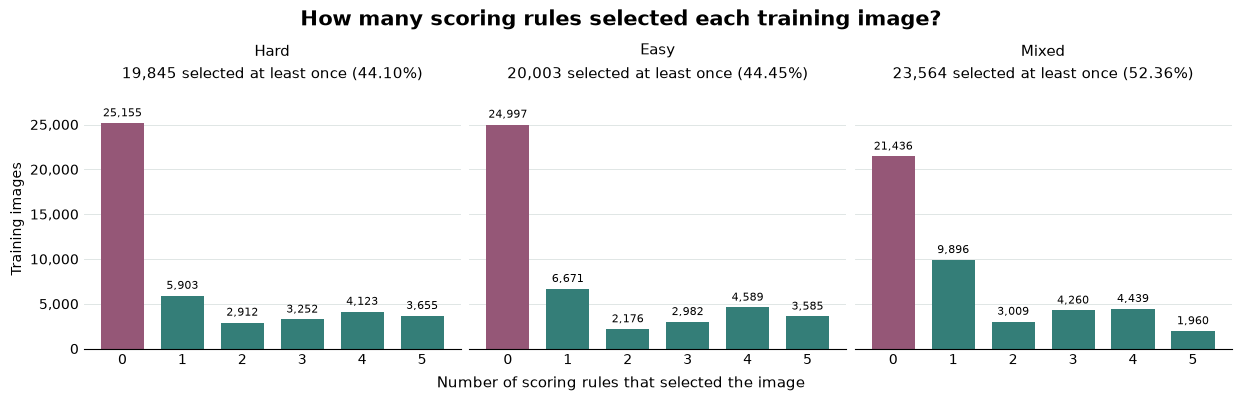

In [14]:
score_keys = ["loss", "average_margin", "el2n", "gradient_norm", "forgetting"]
difficulties = ["hard", "easy", "mixed"]
votes = np.arange(len(score_keys) + 1)
coverage_by_difficulty = {}

for difficulty in difficulties:
    groups = [selected_ids_25[f"{names[key]} · {difficulty}"] for key in score_keys]
    frequency = Counter(image_id for group in groups for image_id in group)
    counts = np.bincount([frequency[image_id] for image_id in train_ids_25], minlength=len(votes))
    assert counts.sum() == len(train_ids_25)
    assert counts @ votes == len(groups) * subset_n
    assert counts[1:].sum() == len(set.union(*groups))
    coverage_by_difficulty[difficulty] = counts

fig, axes = plt.subplots(1, 3, figsize=(12.3, 3.9), sharex=True, sharey=True, layout="constrained")
fig.suptitle("How many scoring rules selected each training image?", fontsize=15, weight="bold")
highest_bar = max(counts.max() for counts in coverage_by_difficulty.values())
for ax, difficulty in zip(axes, difficulties):
    counts = coverage_by_difficulty[difficulty]
    seen = int(counts[1:].sum())
    ax.set_title(f"{difficulty.capitalize()}\n{seen:,} selected at least once ({seen / len(train_ids_25):.2%})",
                 fontsize=10.5, linespacing=1.6, pad=8)
    bars = ax.bar(votes, counts, width=.72, color=["#955777"] + ["#347e78"] * len(score_keys))
    ax.bar_label(bars, labels=[f"{count:,}" for count in counts], fontsize=8, padding=3)
    ax.set_xticks(votes)
    ax.set_ylim(0, highest_bar * 1.15)
    ax.tick_params(length=0)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="y", color="#dde4e3", linewidth=.65)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Training images")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda count, pos: f"{count:,.0f}"))
fig.supxlabel("Number of scoring rules that selected the image", fontsize=11)
plt.show()

#### Inspect the actual images for any pair

Change the two selector names and the class in the next cell. It returns the exact sorted image IDs in the intersection and each difference, then displays up to five examples from the chosen class per group. The default pair compares the two IMP finalists. The gallery uses the project’s local CIFAR-10 data and torchvision. Its sampling seed only controls the thumbnails.

Average margin · easy only: 11,092   |   Both: 158   |   Forgetting · hard only: 11,092


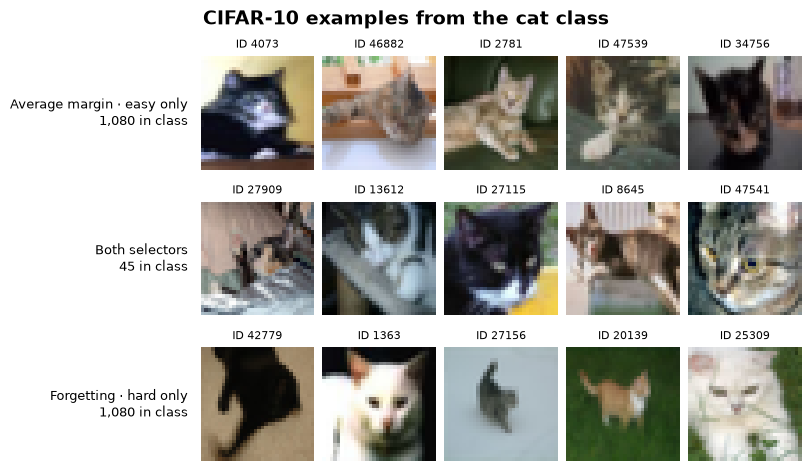

In [15]:
first_selector = "Average margin · easy"
second_selector = "Forgetting · hard"
example_class = "cat"

def compare_image_ids(first, second):
    first_ids, second_ids = selected_ids_25[first], selected_ids_25[second]
    return {"First only": sorted(first_ids - second_ids), "Both": sorted(first_ids & second_ids),
            "Second only": sorted(second_ids - first_ids)}

example_ids = compare_image_ids(first_selector, second_selector)
print(f"{first_selector} only: {len(example_ids['First only']):,}   |   "
      f"Both: {len(example_ids['Both']):,}   |   {second_selector} only: {len(example_ids['Second only']):,}")

from importlib.util import find_spec
data_dir = project / "data"
if find_spec("torchvision") and (data_dir / "cifar-10-batches-py/data_batch_1").is_file():
    from torchvision.datasets import CIFAR10
    cifar_train = CIFAR10(root=str(data_dir), train=True, download=False)
    class_index = cifar_train.classes.index(example_class)
    labels = np.asarray(cifar_train.targets)
    # Independently verify the recorded class quotas against the original dataset labels.
    for ids in selected_ids_25.values():
        assert np.array_equal(np.bincount(labels[sorted(ids)], minlength=10), np.full(10, 1125))
    class_pools = [np.array([i for i in group if labels[i] == class_index], dtype=int)
                   for group in example_ids.values()]
    group_labels = [first_selector + " only", "Both selectors", second_selector + " only"]
    gallery_rng = np.random.default_rng(260)
    fig, axes = plt.subplots(3, 5, figsize=(8.0, 4.65), layout="constrained")
    for row, (group_label, pool) in enumerate(zip(group_labels, class_pools)):
        picks = gallery_rng.choice(pool, size=min(5, len(pool)), replace=False)
        for col, ax in enumerate(axes[row]):
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            if col < len(picks):
                image_id = int(picks[col])
                ax.imshow(cifar_train.data[image_id], interpolation="nearest")
                ax.set_title(f"ID {image_id}", fontsize=8)
            elif col == 0:
                ax.text(.5, .5, "No images", ha="center", va="center", transform=ax.transAxes)
        axes[row, 0].set_ylabel(f"{group_label}\n{len(pool):,} in class", fontsize=9,
                                rotation=0, ha="right", va="center", labelpad=9)
    fig.suptitle(f"CIFAR-10 examples from the {example_class} class", fontsize=14, weight="bold")
    plt.show()
else:
    print("To render thumbnails, open this notebook in the CS260D kernel with the local CIFAR-10 "
          "dataset in data/. The complete image lists are available in example_ids.")

## 9. Which training images do the 18 IMP models miss?

Each model used a different 11,250-image subset to discover its pruning mask. All 18 models then trained on the full 45,000-image split for 200 epochs. Predictions below come from the saved ResNet-32, seed-0, 90%-sparse IMP checkpoints, evaluated on unaugmented images. Held-out validation images provide a comparison for prediction frequency. Only training images were eligible for subset selection.

The notebook reads the 18 matching IMP runs from the prediction cache or regenerates just those runs if the cache is missing.

In [16]:
run_ids_25 = (subset.loc[subset["size"].eq(25)]
              .pivot(index="pruning", columns="selection", values="run")
              .loc[["IMP"], selector_order].to_numpy(dtype=str))
predictions_path = report_25 / "image_predictions_epoch200.npz"
if not predictions_path.exists():
    predictions_path = report_25 / "imp_image_predictions_epoch200.npz"

from common import Images, digest, install_mask, read
from models import Classifier
from torchvision.datasets import CIFAR10
import torch

def collect_predictions_25():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type == "cpu":
        torch.set_num_threads(min(6, torch.get_num_threads()))
    images = Images(CIFAR10(str(project / "data"), train=True, download=False), device)
    labels = images.labels.numpy().astype(np.uint8)
    split = read(root_25 / "splits/cifar10-260.json")
    split_ids = [torch.tensor(split[key]) for key in ("train", "val")]
    train_ids, val_ids = (ids.numpy() for ids in split_ids)
    assert len(train_ids) == 45000 and len(val_ids) == 5000
    assert np.array_equal(np.sort(np.r_[train_ids, val_ids]), np.arange(len(labels)))
    results = np.empty((*run_ids_25.shape, len(labels)), dtype=np.uint8)
    saved_val_confusion = np.empty((*run_ids_25.shape, 10, 10), dtype=np.int64)
    with torch.inference_mode():
        for p, run_group in enumerate(run_ids_25):
            for s, run_id in enumerate(run_group):
                folder = root_25 / "final" / run_id
                record = read(folder / "validation.json")
                mask = read(root_25 / "masks" / record["mask"] / "mask.pt")
                ck = read(folder / "checkpoint.pt")
                assert record["run"] == digest([record["mask"], 200]) == run_id
                assert record["epochs"] == ck["history"][-1]["epoch"] == 200
                assert record["split_id"] == mask["split_id"] == digest(split)
                assert record["recipe"]["arch"] == "resnet32" and record["recipe"]["seed"] == 0
                assert record["pruning"]["method"] == "imp"
                assert record["pruning"]["sparsity"] == .90 and record["subset_spec"]["fraction"] == .25
                model = Classifier("resnet32").to(device)
                install_mask(model, mask["masks"])
                model.load_state_dict(ck["model"])
                model.eval()
                for ids in split_ids:
                    batches = []
                    for batch_ids in ids.split(record["recipe"]["batch_size"]):
                        x, _ = images.batch(batch_ids)
                        batches.append(model(x).argmax(1).to(torch.uint8))
                    results[p, s, ids.numpy()] = torch.cat(batches).cpu().numpy()
                saved_val_confusion[p, s] = record["metrics"]["confusion"]
            print(f"Evaluated {len(run_group)} IMP checkpoints.", flush=True)
    # Publish complete predictions only after every checkpoint finished.
    import tempfile
    import os
    with tempfile.NamedTemporaryFile(dir=predictions_path.parent, suffix=".npz", delete=False) as temp:
        tmp_path = Path(temp.name)
    try:
        np.savez_compressed(tmp_path, run_ids=run_ids_25, labels=labels, train=train_ids, val=val_ids,
                            predictions=results, val_confusion=saved_val_confusion)
        os.replace(tmp_path, predictions_path)
    finally:
        tmp_path.unlink(missing_ok=True)

if not predictions_path.exists():
    collect_predictions_25()

In [17]:
with np.load(predictions_path, allow_pickle=False) as cache:
    matches = np.flatnonzero((cache["run_ids"] == run_ids_25[0]).all(axis=1))
    assert len(matches) == 1, "Could not match the 18 IMP run IDs to one cache row."
    imp_pred_25 = cache["predictions"][matches[0]]
    truth_25 = cache["labels"]
    train_order_25, val_order_25 = cache["train"], cache["val"]
    saved_confusion_25 = cache["val_confusion"][matches[0]]

assert imp_pred_25.shape == (18, 50000) and imp_pred_25.max() < 10
assert np.array_equal(train_order_25, split_25["train"]) and np.array_equal(val_order_25, split_25["val"])
assert len(truth_25) == 50000 and np.all(np.bincount(truth_25[val_order_25], minlength=10) == 500)
imp_wrong_flags_25 = imp_pred_25 != truth_25[None, :]
imp_wrong_25 = imp_wrong_flags_25.sum(axis=0)
imp_correct_25 = len(selector_order) - imp_wrong_25

# Check local inference against the original checkpoint evaluations for just these 18 models.
confusion_25 = np.empty_like(saved_confusion_25)
for s, run_id in enumerate(run_ids_25[0]):
    actual = truth_25[val_order_25].astype(int)
    predicted = imp_pred_25[s, val_order_25]
    confusion_25[s] = np.bincount(actual * 10 + predicted, minlength=100).reshape(10, 10)
    saved_correct = int(all_runs.loc[all_runs["run"].eq(run_id), "correct"].iloc[0])
    assert np.trace(saved_confusion_25[s]) == saved_correct
delta_25 = np.trace(confusion_25, axis1=1, axis2=2) - np.trace(saved_confusion_25, axis1=1, axis2=2)
matrix_match_25 = (confusion_25 == saved_confusion_25).all(axis=(1, 2))
print(f"{matrix_match_25.sum()}/18 validation confusion matrices reproduce exactly. "
      f"The largest change in the number correct is {np.abs(delta_25).max()} out of 5,000.")

4/18 validation confusion matrices reproduce exactly. The largest change in the number correct is 3 out of 5,000.


### Which discovery subsets contain a particular IMP model’s training errors?

Read across a row for one model. **Cell labels are image counts. Color is the percentage of that row’s errors captured.** The row label gives its total number of misclassified training images. Every column is a saved 25% subset. An independent class-balanced draw would cover 25% of a fixed error set on average. A mistake can appear in several columns.

Change `error_model` in the chart cell for the exact counts and both denominators: all errors made by that model and all 11,250 images in the selected subset.

In [18]:
membership_25 = np.stack([np.isin(train_order_25, list(selected_ids_25[name])) for name in selector_order])
subset_sizes_25 = membership_25.sum(axis=1)
assert (subset_sizes_25 == 11250).all()
wrong = imp_wrong_flags_25[:, train_order_25]
total_wrong = wrong.sum(axis=1)
intersections = wrong.astype(np.int32) @ membership_25.T.astype(np.int32)
records_25 = []
for s, predictor in enumerate(selector_order):
    for t, selection in enumerate(selector_order):
        count = int(intersections[s, t])
        records_25.append((predictor, selection, total_wrong[s], count,
                           100 * count / total_wrong[s] if total_wrong[s] else np.nan,
                           100 * count / subset_sizes_25[t]))
error_overlap_25 = pd.DataFrame(records_25, columns=[
    "Model selector", "Subset selector", "All training errors", "Errors in subset",
    "% of model errors in subset", "% of subset misclassified"
]).set_index(["Model selector", "Subset selector"])
assert len(error_overlap_25) == 18**2

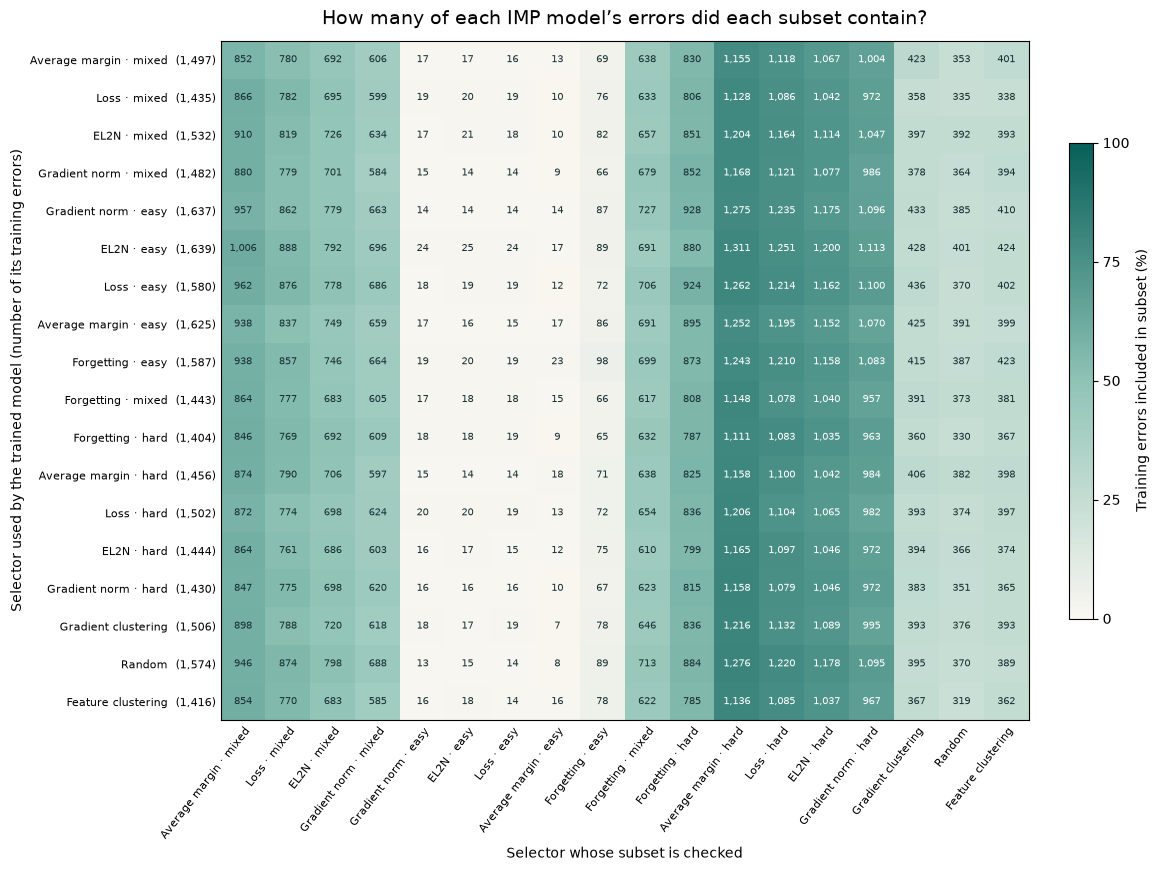

,All training errors,Errors in subset,% of model errors in subset,% of subset misclassified
Subset selector,,,,
Average margin · mixed,"1,416",854,60.31%,7.591%
Loss · mixed,"1,416",770,54.38%,6.844%
EL2N · mixed,"1,416",683,48.23%,6.071%
Gradient norm · mixed,"1,416",585,41.31%,5.200%
Gradient norm · easy,"1,416",16,1.13%,0.142%
EL2N · easy,"1,416",18,1.27%,0.160%
Loss · easy,"1,416",14,0.99%,0.124%
Average margin · easy,"1,416",16,1.13%,0.142%
Forgetting · easy,"1,416",78,5.51%,0.693%


In [19]:
error_model = "Feature clustering"

panel = error_overlap_25
metric = "% of model errors in subset"
cell_counts = panel["Errors in subset"].unstack().loc[cluster_order, cluster_order]
shown = panel[metric].unstack().loc[cluster_order, cluster_order]
totals = panel["All training errors"].groupby(level="Model selector").first()
fig, ax = plt.subplots(figsize=(11.5, 8.6), layout="constrained")
cmap = LinearSegmentedColormap.from_list("errors_in_subset", ["#faf7f1", "#8fc3b6", "#075f59"])
cmap.set_bad("#e6e6e6")
im = ax.imshow(np.ma.masked_invalid(shown.to_numpy()), cmap=cmap, vmin=0, vmax=100, aspect="auto")
ticks = np.arange(len(cluster_order))
ax.set_xticks(ticks, cluster_order, rotation=52, ha="right", rotation_mode="anchor")
ax.set_yticks(ticks, [f"{name}  ({totals[name]:,})" for name in cluster_order])
ax.tick_params(axis="both", labelsize=8, length=0)
ax.set_xlabel("Selector whose subset is checked")
ax.set_ylabel("Selector used by the trained model (number of its training errors)")
ax.set_title("How many of each IMP model’s errors did each subset contain?", fontsize=14, pad=12)
for i in ticks:
    for j in ticks:
        value = shown.iat[i, j]
        label = f"{cell_counts.iat[i, j]:,}" if np.isfinite(value) else "–"
        ax.text(j, i, label, ha="center", va="center", fontsize=7.0,
                color="white" if value > 65 else "#172e32")
bar = fig.colorbar(im, ax=ax, shrink=.70, ticks=[0, 25, 50, 75, 100])
bar.set_label("Training errors included in subset (%)")
plt.show()

display(panel.loc[error_model].loc[cluster_order].style
        .set_caption(f"IMP / {error_model} model against each of the 18 saved subsets")
        .format({"All training errors": "{:,}", "Errors in subset": "{:,}",
                 "% of model errors in subset": "{:.2f}%", "% of subset misclassified": "{:.3f}%"}, na_rep="—"))

For the **feature-clustering IMP model**, hard average margin captured 1,136 of its 1,416 training errors (80.23%). Easy average margin captured 16 (1.13%) and the saved random subset captured 319 (22.53%). All three subsets contain 11,250 images. This measures how well an early selector identifies images a final model still misses. Final validation accuracy answers the separate question of how well the discovered mask generalizes.

### For each image, how many IMP models got it right?

Each label is an exact number of images. Read the gold region for images classified correctly by **0, 1 or 2 of the 18 models**, the definition of *rarely correct* used below. The vertical axis uses a logarithmic count scale so the rare cases and the large all-correct group can be read on the same plot. See `vote_frequencies_25` for all 19 counts in both splits.

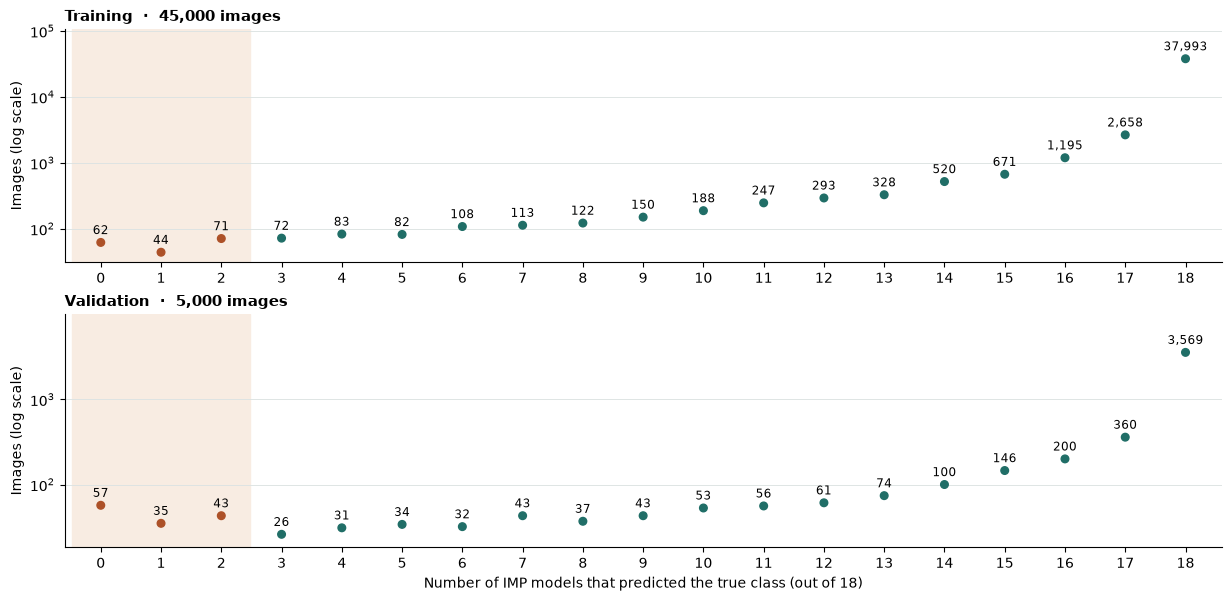

In [20]:
levels_25 = np.arange(19)
vote_frequencies_25 = pd.DataFrame(index=pd.Index(levels_25, name="IMP models correct"))
fig, axes = plt.subplots(2, 1, figsize=(12.2, 5.9), sharex=True, layout="constrained")
for ax, (split_name, image_ids) in zip(axes, [("Training", train_order_25), ("Validation", val_order_25)]):
    counts = np.bincount(imp_correct_25[image_ids], minlength=19)
    vote_frequencies_25[split_name] = counts
    assert counts.sum() == len(image_ids) and counts @ (18 - levels_25) == imp_wrong_25[image_ids].sum()
    ax.axvspan(-.48, 2.48, color="#f8ece2", zorder=0)
    ax.set_yscale("log")
    ax.set_ylim(min(counts[counts > 0]) * .7, counts.max() * 2.8)
    ax.grid(axis="y", linewidth=.65, color="#dce3e2")
    ax.set_axisbelow(True)
    ax.scatter(levels_25, counts, s=30, c=["#ad5128"] * 3 + ["#206e67"] * 16, zorder=3)
    for k, n in enumerate(counts):
        ax.annotate(f"{n:,}", (k, max(n, ax.get_ylim()[0])), xytext=(0, 6),
                    textcoords="offset points", ha="center", fontsize=8.5)
    ax.set_title(f"{split_name}  ·  {len(image_ids):,} images", loc="left", fontsize=11, weight="bold")
    ax.set_ylabel("Images (log scale)")
    ax.spines[["right", "top"]].set_visible(False)
    ax.minorticks_off()
    ax.tick_params(axis="x", labelbottom=True)
axes[-1].set_xticks(levels_25)
axes[-1].set_xlim(-.6, 18.6)
axes[-1].set_xlabel("Number of IMP models that predicted the true class (out of 18)")
plt.show()

### Did any discovery subset include the images that IMP models usually missed?

Here **rarely correct** means at most two of the 18 final models predicted the true class. The second column isolates images all 18 missed. Each percentage uses the number of images in its column heading. One image can belong to several selectors. Each saved subset contains 11,250 of the 45,000 training images. Validation images were held out from every selector.

`rare_image_details_25.loc[image_id]` shows the 18 membership flags for a rarely correct training image. `rare_membership_frequency_25` gives the exact number of images chosen by 0 through 18 selectors.

In [21]:
# Work only with saved discovery sets and images eligible for discovery.
training_wrong = imp_wrong_25[train_order_25]
rare_ids_25 = train_order_25[training_wrong >= 16]
never_correct_ids_25 = train_order_25[training_wrong == 18]
rare_groups_25 = {"Correct 0–2 times": rare_ids_25, "Correct 0 times": never_correct_ids_25}
subset_membership_25 = pd.DataFrame(
    membership_25.T, columns=selector_order, index=pd.Index(train_order_25, name="CIFAR image ID"),
)
assert subset_membership_25.sum().eq(11250).all()
times_in_subset_25 = subset_membership_25.sum(axis=1)
rare_subset_coverage_25 = pd.DataFrame({group: subset_membership_25.loc[ids].sum()
                                       for group, ids in rare_groups_25.items()})
rare_subset_coverage_25 = rare_subset_coverage_25.sort_values(
    list(rare_groups_25), ascending=False, kind="stable")
rare_subset_coverage_25.index.name = "Discovery subset"
coverage_view = pd.DataFrame(index=rare_subset_coverage_25.index)
for group, ids in rare_groups_25.items():
    coverage_view[f"{group} (n = {len(ids)})"] = [
        f"{n:,} ({n / len(ids):.1%})" for n in rare_subset_coverage_25[group]]
display(coverage_view)

# Include zero when computing how many selectors chose each rarely correct image.
rare_membership_frequency_25 = pd.DataFrame(
    {group: times_in_subset_25.loc[ids].value_counts().reindex(range(19), fill_value=0)
     for group, ids in rare_groups_25.items()}
)
rare_membership_frequency_25.index.name = "Number of subsets containing the image"
assert all(rare_membership_frequency_25[group].sum() == len(ids) for group, ids in rare_groups_25.items())
for group, ids in rare_groups_25.items():
    counts = times_in_subset_25.loc[ids]
    print(f"{group} — {counts.gt(0).sum():,}/{len(ids):,} appeared in at least one subset. "
          f"{counts.eq(0).sum():,} appeared in zero. Subsets per image ranged from {counts.min()} "
          f"to {counts.max()} (median {counts.median():g}).")

# These rows list the actual image IDs, so any count in the table can be traced back to its members.
rare_image_details_25 = subset_membership_25.loc[rare_ids_25].copy()
rare_image_details_25.insert(0, "Subsets containing image", times_in_subset_25.loc[rare_ids_25])
rare_image_details_25.insert(0, "IMP models correct", 18 - imp_wrong_25[rare_ids_25])
rare_image_details_25 = rare_image_details_25.sort_values(["IMP models correct", "Subsets containing image"])
example_rare_id_25 = int(rare_image_details_25.index[0])
included_by = subset_membership_25.columns[subset_membership_25.loc[example_rare_id_25]].tolist()
print(f"{18 - imp_wrong_25[example_rare_id_25]}/18 models correctly classified training image "
      f"{example_rare_id_25:,}. Its {len(included_by)} discovery subsets were {', '.join(included_by)}.")

,Correct 0–2 times (n = 177),Correct 0 times (n = 62)
Discovery subset,,
Average margin · hard,172 (97.2%),62 (100.0%)
Loss · hard,164 (92.7%),61 (98.4%)
Average margin · mixed,152 (85.9%),56 (90.3%)
EL2N · hard,152 (85.9%),56 (90.3%)
Loss · mixed,137 (77.4%),53 (85.5%)
Gradient norm · hard,133 (75.1%),47 (75.8%)
Forgetting · hard,129 (72.9%),50 (80.6%)
Forgetting · mixed,120 (67.8%),48 (77.4%)
EL2N · mixed,118 (66.7%),43 (69.4%)


Correct 0–2 times — 177/177 appeared in at least one subset. 0 appeared in zero. Subsets per image ranged from 1 to 13 (median 9).
Correct 0 times — 62/62 appeared in at least one subset. 0 appeared in zero. Subsets per image ranged from 3 to 13 (median 9.5).
0/18 models correctly classified training image 19,096. Its 3 discovery subsets were Loss · hard, Average margin · hard, Average margin · mixed.


### Inspect a rarely correct image

The example starts with an image all 18 IMP models missed, choosing one that appears in the fewest discovery subsets. Change `image_id` to look up another image. The table pairs each model’s prediction with membership in the subset that discovered its mask. For comparison, the earlier example, truck **360**, was classified correctly by 9 of the 18 models and belonged to six subsets.

In [22]:
from common import CLASSES

def image_votes_25(image_id):
    """Show each IMP model's predicted class and the matching selector's discovery membership."""
    if not isinstance(image_id, (int, np.integer)) or not 0 <= image_id < len(truth_25):
        raise ValueError("Use an original CIFAR training-file ID from 0 to 49,999.")
    eligible = image_id in train_ids_25
    picked = [image_id in selected_ids_25[name] for name in selector_order]
    prediction = imp_pred_25[:, image_id]
    print(f"Image {image_id}  ·  {'Training' if eligible else 'Held-out validation'}  ·  "
          f"True class: {CLASSES[truth_25[image_id]]}  ·  Correct: {imp_correct_25[image_id]}/18")
    print(f"Selected by {sum(picked)}/18 discovery subsets." if eligible else
          "Held-out validation images are ineligible for all discovery subsets.")
    return pd.DataFrame({"Selector": selector_order,
                         "In discovery subset": picked if eligible else [pd.NA] * 18,
                         "IMP predicted": np.asarray(CLASSES)[prediction],
                         "Correct": prediction == truth_25[image_id]}).set_index("Selector")

image_id = example_rare_id_25   # Change this to an original CIFAR training-file ID.
display(image_votes_25(image_id))

Image 19096  ·  Training  ·  True class: dog  ·  Correct: 0/18
Selected by 3/18 discovery subsets.


,In discovery subset,IMP predicted,Correct
Selector,,,
Random,False,cat,False
Feature clustering,False,airplane,False
Gradient clustering,False,cat,False
Loss · easy,False,cat,False
Loss · hard,True,cat,False
Loss · mixed,False,cat,False
Average margin · easy,False,cat,False
Average margin · hard,True,cat,False
Average margin · mixed,True,cat,False


### Can hard-score combinations find the training images IMP usually misses?

The five score-based selectors saved a hardness value for **every training image** at the epoch-10 reference. The saved `scores.pt` files pair each hardness value with its original training image ID. The two clustering methods save class-local cluster assignments, and random selection has no hardness ranking. Higher values mean harder. For forgetting, the score counts correct-to-incorrect transitions during those ten epochs. Images that the reference never classified correctly get a score of 11. Each early observation uses an augmented image seen during dense training. Many forgetting scores tie, so the replay uses the original class-seeded shuffle before the stable sort. The outcome here comes later, from the 18 final IMP models. **Rarely correct** means correct for at most two of those models.

**Equal-budget comparison.** Rank within each class, reproduce the saved hard-25% selections, then try all ten pairs. Each rule in a pair takes turns picking its best remaining image, skipping duplicates. Each supplies 5,625 picks across the ten classes. This gives every rule and pair 11,250 distinct images. *Rare recall* is the share of all rarely correct training images captured. *Error votes captured* is the share of all incorrect model–image predictions captured, so an image all 18 models miss contributes 18 votes.

In [23]:
from itertools import combinations, cycle
from common import generator
import json
import torch

# Reproduce the original within-class hard ranking, including its seeded tie-breaks.
class_rankings_25 = {}
for subset_id in sorted(referenced_subsets):
    folder = root_25 / "subsets" / subset_id
    record = json.loads((folder / "subset.json").read_text(encoding="utf-8"))
    spec = record["spec"]
    if spec.get("difficulty") != "hard":
        continue
    name = names[spec["method"]]
    saved = torch.load(folder / "scores.pt", map_location="cpu", weights_only=True)
    ids, score = saved["train_ids"], saved["hardness"]
    assert np.array_equal(ids.numpy(), train_order_25) and torch.isfinite(score).all()
    if spec["method"] == "forgetting":
        forgetting_scores_25 = score.numpy()
        never_learned_score_25 = spec["reference_epoch"] + 1
    labels = torch.as_tensor(truth_25[ids.numpy()])
    ranked = []
    for class_id in range(10):
        within = torch.where(labels == class_id)[0]
        rng = generator(record["recipe"]["seed"] + class_id)
        shuffled = within[torch.randperm(len(within), generator=rng)]
        ordered = shuffled[torch.argsort(score[shuffled], descending=True, stable=True)]
        ranked.append(ids[ordered].tolist())
    assert {i for order in ranked for i in order[:1125]} == selected_ids_25[f"{name} · hard"]
    class_rankings_25[name] = ranked
assert len(class_rankings_25) == 5

def half_quota_pair(first, second):
    chosen = set()
    for class_id, (a, b) in enumerate(zip(first, second)):
        # Switch who receives the odd slot in each of the ten classes.
        turns = (iter(a), iter(b)) if class_id % 2 == 0 else (iter(b), iter(a))
        local = set()
        for turn in cycle(turns):
            local.add(next(image_id for image_id in turn if image_id not in local))
            if len(local) == 1125:
                break
        chosen.update(local)
    return chosen

# At 25%, singles and pairs all get the same budget. At 50%, deduplicate each literal union.
hybrid_ids_25, union50_ids_25 = {}, {}
for name, ranked in class_rankings_25.items():
    hybrid_ids_25[name] = {i for order in ranked for i in order[:1125]}
    union50_ids_25[name] = {i for order in ranked for i in order[:2250]}
for first, second in combinations(sorted(class_rankings_25), 2):
    pair = f"{first} + {second}"
    hybrid_ids_25[pair] = half_quota_pair(class_rankings_25[first], class_rankings_25[second])
    union50_ids_25[pair] = union50_ids_25[first] | union50_ids_25[second]
assert len(hybrid_ids_25) == len(union50_ids_25) == 15
for chosen in hybrid_ids_25.values():
    assert np.array_equal(np.bincount(truth_25[list(chosen)], minlength=10), [1125] * 10)

train_votes_25 = imp_wrong_25[train_order_25]
rare_total_25 = int((train_votes_25 >= 16).sum())
never_correct_total_25 = int((train_votes_25 == 18).sum())
ever_missed_total_25 = int((train_votes_25 > 0).sum())

def score_coverage(candidates):
    rows = []
    for rule, chosen in candidates.items():
        ids = np.asarray(sorted(chosen))
        votes = imp_wrong_25[ids]
        rows.append({
            "Rule": rule, "Selected": len(ids), "Rare captured": int((votes >= 16).sum()),
            "Rare recall (%)": 100 * (votes >= 16).sum() / rare_total_25,
            "Rare per 1,000 selected": 1000 * (votes >= 16).mean(),
            "All 18 wrong captured": int((votes == 18).sum()),
            "Ever missed captured": int((votes > 0).sum()),
            "Error votes captured (%)": 100 * votes.sum() / train_votes_25.sum(),
        })
    return pd.DataFrame(rows).set_index("Rule")

hybrid_coverage_25 = score_coverage(hybrid_ids_25).sort_values(
    ["Rare captured", "Error votes captured (%)"], ascending=False)
union50_coverage_25 = score_coverage(union50_ids_25).sort_values(
    ["Rare captured", "Selected"], ascending=[False, True])
print(f"Training targets: {rare_total_25:,} rarely correct, {never_correct_total_25:,} wrong under all 18, "
      f"{ever_missed_total_25:,} missed by at least one. Each model-image mistake counts as one error vote.")
rare_in_train = train_votes_25 >= 16
never_learned_early = forgetting_scores_25 == never_learned_score_25
print(f"Of the {rare_total_25} rarely correct images, {int((rare_in_train & never_learned_early).sum())} "
      f"were never learned by the epoch-10 reference and received forgetting score {never_learned_score_25}.")
display(hybrid_coverage_25.drop(columns=["Selected", "Rare per 1,000 selected"]).style
        .format({"Rare recall (%)": "{:.1f}", "Error votes captured (%)": "{:.1f}"})
        .set_caption("Equal budget: 11,250 images for every single rule and every 50:50 pair"))

Training targets: 177 rarely correct, 62 wrong under all 18, 7,007 missed by at least one. Each model-image mistake counts as one error vote.
Of the 177 rarely correct images, 109 were never learned by the epoch-10 reference and received forgetting score 11.


,Rare captured,Rare recall (%),All 18 wrong captured,Ever missed captured,Error votes captured (%)
Rule,,,,,
Average margin,172,97.2,62,4711,79.3
Average margin + Loss,169,95.5,62,4688,79.5
Average margin + EL2N,168,94.9,61,4620,78.2
Average margin + Forgetting,165,93.2,59,4481,75.3
Average margin + Gradient norm,164,92.7,59,4520,76.7
Loss,164,92.7,61,4425,75.7
EL2N + Loss,164,92.7,61,4396,75.0
Gradient norm + Loss,161,91.0,61,4281,73.0
Forgetting + Loss,159,89.8,60,4295,72.6


### What if each rule selects the hardest half of the training split?

Take the hardest 50% of each class under each score and compute the union. Each single rule selects 22,500 images, and pairs may select more. Read recall together with the number selected and the number of rarely correct images found per 1,000 selections. These are retrospective error-coverage comparisons for one seed. Measuring sparse-model accuracy with a hybrid would require discovering a new mask and training it.

In [24]:
display(union50_coverage_25[["Selected", "Rare captured", "All 18 wrong captured", "Ever missed captured", "Error votes captured (%)", "Rare per 1,000 selected"]].style
        .format({"Selected": "{:,}", "Error votes captured (%)": "{:.1f}", "Ever missed captured": "{:,}", "Rare per 1,000 selected": "{:.1f}"})
        .set_caption("Larger budgets: hardest 50% per score, with duplicates counted once per pair"))

,Selected,Rare captured,All 18 wrong captured,Ever missed captured,Error votes captured (%),"Rare per 1,000 selected"
Rule,,,,,,
Average margin,"22,500",177,62,"6,327",95.0,7.9
Average margin + Loss,"27,558",177,62,"6,694",98.0,6.4
Average margin + EL2N,"27,588",177,62,"6,694",98.0,6.4
Average margin + Gradient norm,"27,752",177,62,"6,691",98.0,6.4
Average margin + Forgetting,"27,930",177,62,"6,633",97.4,6.3
Forgetting + Loss,"29,696",177,62,"6,708",97.9,6.0
EL2N + Forgetting,"29,700",177,62,"6,708",98.0,6.0
Forgetting + Gradient norm,"29,775",177,62,"6,690",97.6,5.9
EL2N,"22,500",176,62,"6,198",93.8,7.8


**What changed when the scores were combined?** At 11,250 images, hard average margin captured the most distinct training images missed at least once (4,711 of 7,007) and the most rarely correct images (172 of 177). Margin plus loss captured 169 rarely correct images and a slightly larger share of all model–image mistakes (79.54% versus 79.34%). Replacing half of forgetting’s picks with margin increased rarely correct coverage from 129 to 165. It picked up 37 such images and dropped one.

With the larger unions, the hardest half by margin alone already covered 177 of 177 rarely correct images. Adding the hardest half by forgetting raised coverage of images missed at least once from 6,327 to 6,633 while increasing the subset from 22,500 to 27,930. The largest coverage on that broader target was 6,708 of 7,007, achieved by forgetting plus loss (29,696 images) and forgetting plus EL2N (29,700 images). These counts come from scoring the existing seed-0 predictions. The hybrids have no measured pruning accuracy in this sweep.

### Which rare images does each rule contribute?

For the two saved hard-25% subsets, the grid divides rarely correct training images by membership in average margin and forgetting. The four cells are disjoint and sum to the number of rarely correct training images. Compare the off-diagonal cells to see how many additional rare images one rule contributes to the other’s existing selection.

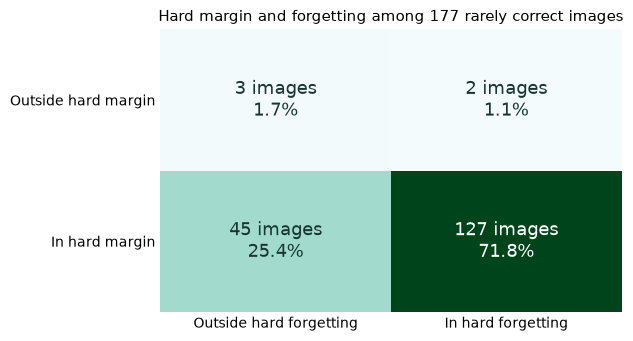

In [25]:
rare = set(rare_ids_25)
margin_set = selected_ids_25["Average margin · hard"]
forget_set = selected_ids_25["Forgetting · hard"]
layout = [[rare - (margin_set | forget_set), rare & (forget_set - margin_set)],
          [rare & (margin_set - forget_set), rare & margin_set & forget_set]]
counts = np.asarray([[len(ids) for ids in row] for row in layout])
assert counts.sum() == len(rare)
fig, ax = plt.subplots(figsize=(6.2, 3.3), layout="constrained")
ax.imshow(counts, cmap="BuGn", vmin=0, vmax=counts.max(), aspect="auto")
for i in range(2):
    for j in range(2):
        n = counts[i, j]
        ax.text(j, i, f"{n} images\n{n / len(rare):.1%}", ha="center", va="center",
                fontsize=13, color="white" if n == counts.max() else "#183733")
ax.set_xticks([0, 1], ["Outside hard forgetting", "In hard forgetting"])
ax.set_yticks([0, 1], ["Outside hard margin", "In hard margin"])
ax.tick_params(length=0)
ax.set_title(f"Hard margin and forgetting among {len(rare)} rarely correct images", fontsize=11)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

<a id="sparsity-comparison"></a>

## 10. What changes when weight sparsity decreases from 90% to 80%?

Both sweeps used ResNet-32, seed 0, 11,250 training images for each 25% discovery subset, and 200 epochs of final training on all 45,000 training images. Both evaluated on the same 5,000 validation images. At 90% sparsity, 10% of eligible weights survive. At 80%, 20% survive. Gains below are **80% minus 90%**, in percentage points (pp).

The main comparison pairs each of 18 selector settings with each of four data-dependent pruners. The dense reference, four full-training-set pruning controls, and data-free SynFlow appear separately below. Each selector contributes one result per pruner to the means. [80% sweep records](runs/resnet32-s0-sub25-s80/sweeps/a353315af265f84965fd/runs.csv) · [90% sweep records](runs/resnet32-s0-sub25-s90/sweeps/e138bdd3b6e5901d553d/runs.csv)

In [26]:
sparsity_reports = {
    90: sweep_dirs[25],
    80: project / "runs/resnet32-s0-sub25-s80/sweeps/a353315af265f84965fd",
}

def read_sparsity_sweep(level, folder):
    root = folder.parents[1]
    config = json.loads((folder / "config.json").read_text(encoding="utf-8"))
    assert config["fractions"] == [.25] and config["sparsities"] == [level / 100]
    assert config["architectures"] == ["resnet32"] and config["seeds"] == [0]
    assert config["split_seed"] == 260 and config["reference_epochs"] == [10] and config["rounds"] == 8
    frame = pd.read_csv(folder / "runs.csv")
    execution = json.loads((folder / "execution.json").read_text(encoding="utf-8"))
    assert len(frame) == frame["run"].nunique() == len(execution["runs"]) == 77
    assert set(frame["run"]) == {event["run"] for event in execution["runs"]}
    assert frame["target_sparsity"].eq(level / 100).all() and frame["fraction"].dropna().eq(.25).all()
    assert frame["architecture"].eq("resnet32").all() and frame["seed"].eq(0).all()
    assert frame["partition"].eq("validation").all() and frame["final_epochs"].eq(200).all()
    split = json.loads((root / "splits/cifar10-260.json").read_text(encoding="utf-8"))
    n_val = len(split["val"])
    assert n_val == 5000 and len(split["train"]) == 45000
    local_dense = json.loads((root / "baselines" / baseline_path.parent.name / baseline_path.name)
                             .read_text(encoding="utf-8"))["metrics"]
    assert local_dense["confusion"] == dense["confusion"]
    frame["correct"] = (frame["accuracy"] * n_val).round().astype(int)
    assert np.allclose(frame["correct"], frame["accuracy"] * n_val)
    frame["pruning"] = frame["pruner"].map({**pruners, "synflow": "SynFlow"})
    frame["selection"] = frame["selector"].map(names)
    scored = frame["difficulty"].notna()
    frame.loc[scored, "selection"] += " · " + frame.loc[scored, "difficulty"]

    # Run and subset IDs can repeat across archives. Read actual membership from each sweep's own folder.
    sets = {}
    for record in frame.loc[frame["pruner"].eq("imp") & frame["fraction"].notna()].itertuples():
        final = json.loads((root / "final" / record.run / "validation.json").read_text(encoding="utf-8"))
        subset_id = final["pruning"]["subset"]
        saved = json.loads((root / "subsets" / subset_id / "subset.json").read_text(encoding="utf-8"))
        sets[record.selection] = set(saved["ids"])
        assert len(sets[record.selection]) == 11250 and saved["class_counts"] == [1125] * 10
    assert set(sets) == set(selector_order)
    return frame.assign(sparsity_pct=level), sets, split

sparsity_frames, sparsity_sets, sparsity_splits = [], {}, {}
for level, folder in sparsity_reports.items():
    frame, sets, split = read_sparsity_sweep(level, folder)
    sparsity_frames.append(frame)
    sparsity_sets[level] = sets
    sparsity_splits[level] = split
n_val = len(sparsity_splits[90]["val"])
assert sparsity_splits[80] == sparsity_splits[90]
sparsity_frame = pd.concat(sparsity_frames, ignore_index=True)
sparsity_subset = sparsity_frame.loc[sparsity_frame["fraction"].notna()].copy()
sparsity_counts = sparsity_subset.pivot(index=["selection", "pruning"], columns="sparsity_pct", values="correct")
sparsity_order = pd.MultiIndex.from_product([selector_order, methods], names=["selection", "pruning"])
assert set(sparsity_counts.index) == set(sparsity_order)
sparsity_counts = sparsity_counts.loc[sparsity_order, [90, 80]]
assert sparsity_counts.shape == (72, 2) and sparsity_counts.notna().all().all()
sparsity_counts["Gain (images)"] = sparsity_counts[80] - sparsity_counts[90]
sparsity_pairs = (sparsity_counts * (100 / n_val)).rename(columns={"Gain (images)": "Gain (pp)"})
replacements = pd.Series({name: len(sparsity_sets[90][name] - sparsity_sets[80][name])
                          for name in selector_order}, name="Images replaced")

In [27]:
from IPython.display import Markdown

pruner_avg = sparsity_pairs.groupby(level="pruning").mean().reindex(methods)
pruner_avg.loc["All 72 configurations"] = sparsity_pairs.mean()
gain_counts = sparsity_counts["Gain (images)"]
kept_labels = replacements.index[replacements.eq(0)]
same_ids = sparsity_pairs.loc[sparsity_pairs.index.get_level_values("selection").isin(kept_labels)]
display(Markdown(
    f"**{gain_counts.gt(0).sum()} of {len(gain_counts)} configurations improved** when sparsity decreased "
    f"from 90% to 80%. Mean accuracy increased from **{sparsity_pairs[90].mean():.2f}%** to "
    f"**{sparsity_pairs[80].mean():.2f}%**. Individual gains ranged from "
    f"**{sparsity_pairs['Gain (pp)'].min():.2f}** to **{sparsity_pairs['Gain (pp)'].max():.2f}** percentage points. "
    f"The shared unpruned baseline scored **{dense_pct:.2f}%**."
))
display(pruner_avg.rename(columns={90:"90% sparse · accuracy", 80:"80% sparse · accuracy"}).style
        .format({**dict.fromkeys(["90% sparse · accuracy", "80% sparse · accuracy"], "{:.2f}%"),
                 "Gain (pp)":"{:+.2f}"}))
changed = ", ".join(f"{label} ({int(n):,} replaced)" for label, n in replacements[replacements.gt(0)].items())
display(Markdown(
    f"**Subset membership.** {len(kept_labels)} of 18 selectors used identical image IDs in both sweeps. "
    f"The differences were {changed}. Restricting the comparison to the **{len(same_ids)}** configurations "
    f"with identical image IDs gives a mean gain of **{same_ids['Gain (pp)'].mean():.2f} pp**."
))

**72 of 72 configurations improved** when sparsity decreased from 90% to 80%. Mean accuracy increased from **90.56%** to **91.85%**. Individual gains ranged from **0.10** to **2.34** percentage points. The shared unpruned baseline scored **94.06%**.

sparsity_pct,90% sparse · accuracy,80% sparse · accuracy,Gain (pp)
pruning,,,
Magnitude,90.55%,91.77%,+1.22
IMP,90.73%,91.88%,+1.14
SNIP,90.42%,91.84%,+1.42
GraSP,90.55%,91.92%,+1.37
All 72 configurations,90.56%,91.85%,+1.29


**Subset membership.** 16 of 18 selectors used identical image IDs in both sweeps. The differences were Gradient clustering (107 replaced), Loss · mixed (1 replaced). Restricting the comparison to the **64** configurations with identical image IDs gives a mean gain of **1.28 pp**.

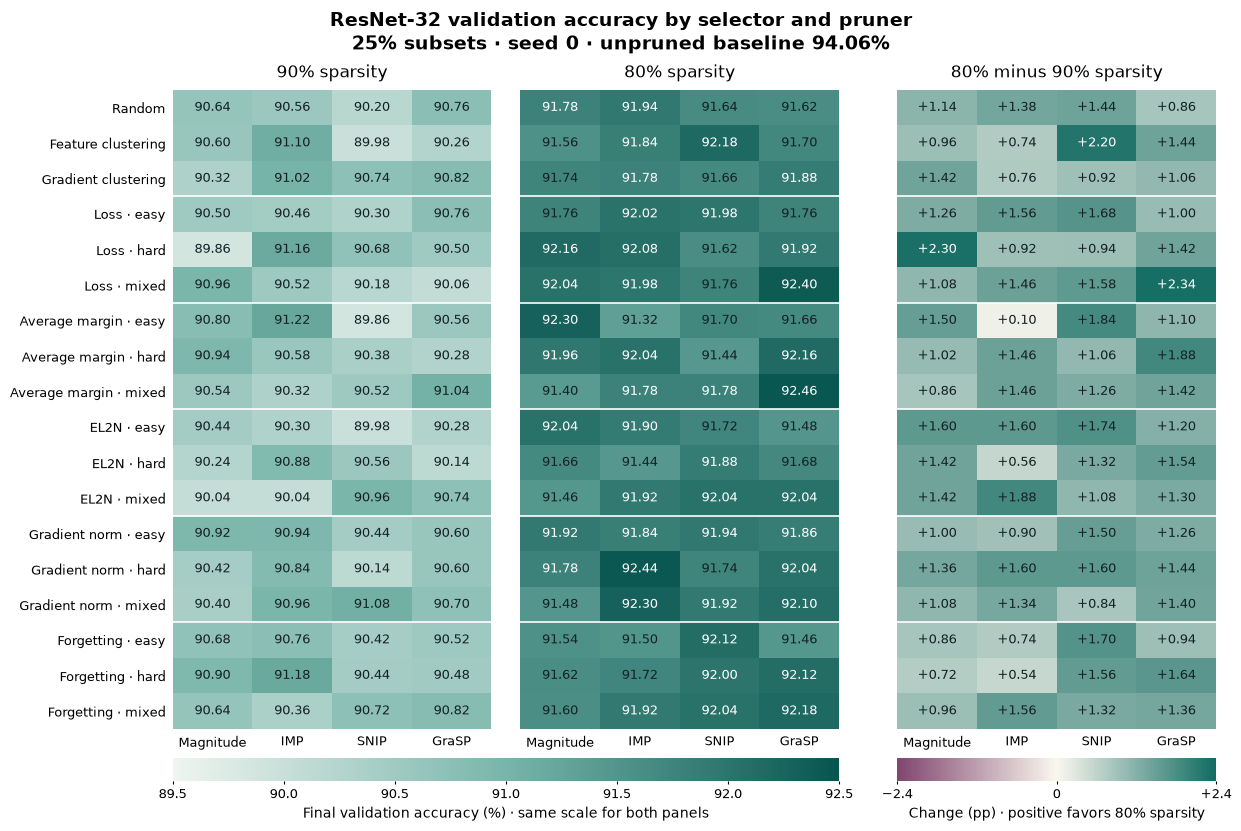

In [28]:
heatmap_tables = [
    sparsity_pairs[column].unstack("pruning").loc[selector_order, methods]
    for column in (90, 80, "Gain (pp)")
]
absolute_values = np.stack([table.to_numpy(dtype=float) for table in heatmap_tables[:2]])
accuracy_low = np.floor(absolute_values.min() * 2) / 2
accuracy_high = max(accuracy_low + .5, np.ceil(absolute_values.max() * 2) / 2)
max_gain = np.abs(heatmap_tables[2].to_numpy(dtype=float)).max()
gain_limit = max(.1, np.ceil(max_gain * 10) / 10)
accuracy_cmap = LinearSegmentedColormap.from_list("sparsity_accuracy", ["#eff5f0", "#78b5aa", "#07554f"])
gain_cmap = LinearSegmentedColormap.from_list("sparsity_gain", ["#80466f", "#faf7ef", "#116b61"])

fig = plt.figure(figsize=(12.3, 8.2), layout="constrained")
grid = fig.add_gridspec(2, 3, height_ratios=[28, 1], wspace=.07)
fig.suptitle(f"ResNet-32 validation accuracy by selector and pruner\n"
             f"25% subsets · seed 0 · unpruned baseline {dense_pct:.2f}%", fontsize=14, weight="bold")
heatmap_images = []
for panel, (title, table) in enumerate(zip(["90% sparsity", "80% sparsity", "80% minus 90% sparsity"], heatmap_tables)):
    ax = fig.add_subplot(grid[0, panel])
    gain_panel = panel == 2
    values = table.to_numpy(dtype=float)
    image = ax.imshow(values, aspect="auto", interpolation="nearest",
                      cmap=gain_cmap if gain_panel else accuracy_cmap,
                      vmin=-gain_limit if gain_panel else accuracy_low,
                      vmax=gain_limit if gain_panel else accuracy_high)
    heatmap_images.append(image)
    ax.set_title(title, fontsize=12, pad=9)
    ax.set_xticks(range(len(methods)), labels=methods)
    ax.set_yticks(range(len(selector_order)), labels=selector_order if panel == 0 else [])
    ax.tick_params(length=0, pad=5, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for boundary in range(3, len(selector_order), 3):
        ax.axhline(boundary - .5, color="white", linewidth=1.2)
    for (row, col), value in np.ndenumerate(values):
        rgb = np.array(image.cmap(image.norm(value))[:3])
        linear_rgb = np.where(rgb <= .04045, rgb / 12.92, ((rgb + .055) / 1.055) ** 2.4)
        lightness = linear_rgb @ [.2126, .7152, .0722]
        label = f"{value:+.2f}" if gain_panel and abs(value) >= .005 else f"{abs(value):.2f}"
        ax.text(col, row, label, ha="center", va="center", fontsize=9,
                color="white" if lightness < .19 else "#152125")

accuracy_bar = fig.colorbar(heatmap_images[0], cax=fig.add_subplot(grid[1, :2]), orientation="horizontal")
accuracy_bar.set_label("Final validation accuracy (%) · same scale for both panels", fontsize=10)
gain_bar = fig.colorbar(heatmap_images[2], cax=fig.add_subplot(grid[1, 2]), orientation="horizontal",
                       ticks=[-gain_limit, 0, gain_limit])
gain_bar.set_ticklabels([f"−{gain_limit:.1f}", "0", f"+{gain_limit:.1f}"])
gain_bar.set_label("Change (pp) · positive favors 80% sparsity", fontsize=10)
for colorbar in (accuracy_bar, gain_bar):
    colorbar.outline.set_visible(False)
    colorbar.ax.tick_params(labelsize=9, length=2)
plt.show()

### Leading configurations and full-data controls

The first table selects the highest validation accuracy at each sparsity and shows how that *same* selector and pruner performed at the other sparsity. The second compares the four full-data discovery runs and data-free SynFlow. Each difference of 0.02 pp represents one validation image.

In [29]:
# Include ties at each sparsity, then show how those same configurations performed at the other sparsity.
leader_frames = []
for level in (80, 90):
    top = sparsity_pairs.index[sparsity_counts[level].eq(sparsity_counts[level].max())]
    for key in top:
        leader_frames.append((f"Best at {level}%", *key, *sparsity_pairs.loc[key, [90, 80, "Gain (pp)"]]))
leaders = pd.DataFrame(leader_frames, columns=["Selected by", "Selector", "Pruner", "90% accuracy", "80% accuracy", "Gain (pp)"])
display(leaders.set_index(["Selected by", "Selector", "Pruner"]).style.format(
    {"90% accuracy": "{:.2f}%", "80% accuracy": "{:.2f}%", "Gain (pp)": "{:+.2f}"}))

sparsity_controls = sparsity_frame.loc[sparsity_frame["fraction"].isna()].pivot(
    index=["selector", "pruning"], columns="sparsity_pct", values="correct")
control_rows = [("full", method) for method in methods] + [("data-free", "SynFlow")]
assert set(sparsity_controls.index) == set(control_rows)
control_acc = sparsity_controls.loc[control_rows, [90, 80]] * (100 / n_val)
control_acc.index = [f"Full-data {method}" for method in methods] + ["Data-free SynFlow"]
control_acc["Gain (pp)"] = control_acc[80] - control_acc[90]
display(control_acc.rename(columns={90:"90% accuracy", 80:"80% accuracy"}).style.format(
    {"90% accuracy": "{:.2f}%", "80% accuracy": "{:.2f}%", "Gain (pp)": "{:+.2f}"})
    .set_caption(f"Controls at epoch 200 · shared dense reference {dense_pct:.2f}%"))

for level in [90, 80]:
    outcomes = {}
    for method in methods:
        diff = sparsity_counts.xs(method, level="pruning")[level] - sparsity_controls.loc[("full", method), level]
        outcomes[method] = int(diff.gt(0).sum())
    print(f"Subsets beating their own full-data control at {level}% sparsity (of 18 per pruner): " +
          ", ".join(f"{name} {count}/18" for name, count in outcomes.items()))

,,,90% accuracy,80% accuracy,Gain (pp)
Selected by,Selector,Pruner,,,
Best at 80%,Average margin · mixed,GraSP,91.04%,92.46%,+1.42
Best at 90%,Average margin · easy,IMP,91.22%,91.32%,+0.10


sparsity_pct,90% accuracy,80% accuracy,Gain (pp)
Full-data Magnitude,90.70%,91.90%,+1.20
Full-data IMP,90.14%,92.26%,+2.12
Full-data SNIP,90.24%,91.98%,+1.74
Full-data GraSP,90.28%,90.82%,+0.54
Data-free SynFlow,90.42%,91.80%,+1.38


Subsets beating their own full-data control at 90% sparsity (of 18 per pruner): Magnitude 5/18, IMP 17/18, SNIP 12/18, GraSP 13/18
Subsets beating their own full-data control at 80% sparsity (of 18 per pruner): Magnitude 6/18, IMP 2/18, SNIP 5/18, GraSP 18/18


### How does the sparsity gain vary by selection difficulty and image class?

For difficulty, each row averages the same five scoring rules and four pruning methods. Each point in the class plot averages all 72 subset configurations at one sparsity, with 500 validation images in each class.

In [30]:
# Aggregate the 5 scoring rules × 4 pruners within each difficulty. Random and clustering have no difficulty.
difficulty_rows = sparsity_subset.dropna(subset=["difficulty"])
assert difficulty_rows.groupby(["difficulty", "sparsity_pct"]).size().eq(20).all()
difficulty_comp = (difficulty_rows.groupby(["difficulty","sparsity_pct"])["correct"].mean()
                   .unstack().loc[["easy","hard","mixed"], [90,80]] * (100 / n_val))
difficulty_comp["Gain (pp)"] = difficulty_comp[80] - difficulty_comp[90]
display(difficulty_comp.rename(columns={90:"90% accuracy",80:"80% accuracy"}).style.format(
    {"90% accuracy":"{:.3f}%","80% accuracy":"{:.3f}%","Gain (pp)":"{:+.3f}"}).set_caption(
    "Mean over 20 selector–pruner combinations per difficulty and sparsity"))

sparsity_pct,90% accuracy,80% accuracy,Gain (pp)
difficulty,,,
easy,90.537%,91.791%,+1.254
hard,90.560%,91.875%,+1.315
mixed,90.580%,91.930%,+1.350


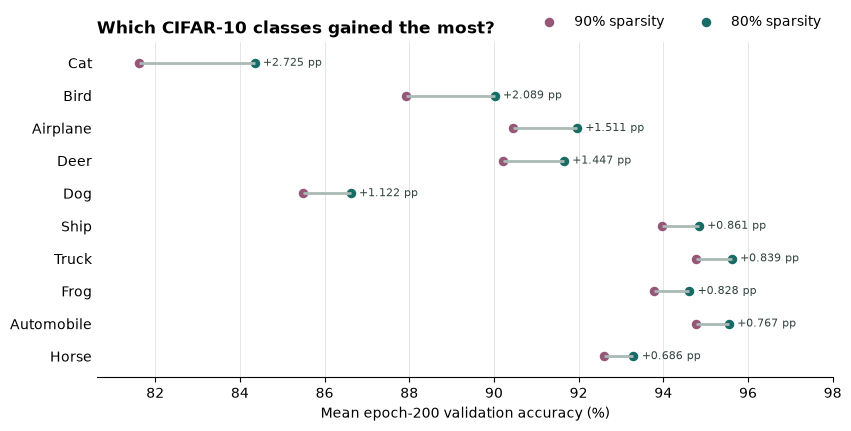

In [31]:
# All 72 subset configurations have 500 validation images in each class.
class_cols = [col for col in sparsity_subset if col.endswith("_accuracy")]
assert len(class_cols) == 10
class_acc = (sparsity_subset.groupby("sparsity_pct")[class_cols].mean().T[[90, 80]] * 100)
class_acc.index = class_acc.index.str.removesuffix("_accuracy").str.capitalize()
class_acc["Gain (pp)"] = class_acc[80] - class_acc[90]
class_acc = class_acc.sort_values("Gain (pp)", ascending=True)
assert np.isclose(class_acc["Gain (pp)"].mean(), sparsity_pairs["Gain (pp)"].mean())
fig, ax = plt.subplots(figsize=(8.4, 4.2), layout="constrained")
positions = np.arange(len(class_acc))
ax.hlines(positions, class_acc[90], class_acc[80], color="#a9bab7", lw=2)
ax.scatter(class_acc[90], positions, label="90% sparsity", color="#955678", s=34)
ax.scatter(class_acc[80], positions, label="80% sparsity", color="#196c65", s=34)
for y, (right, gain) in enumerate(zip(class_acc[80], class_acc["Gain (pp)"])):
    ax.annotate(f"{gain:+.3f} pp", (right,y), xytext=(6,0), textcoords="offset points",
                ha="left", va="center", fontsize=8, color="#314340")
ax.set_yticks(positions, class_acc.index)
ax.set_xlabel("Mean epoch-200 validation accuracy (%)")
ax.set_title("Which CIFAR-10 classes gained the most?", loc="left", weight="bold")
ax.set_xlim(class_acc[[90,80]].min().min()-1, class_acc[[90,80]].max().max()+2.4)
ax.set_ylim(-.65, len(class_acc)-.35)
ax.spines[["right","top","left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#dde4e3", lw=.6)
ax.set_axisbelow(True)
ax.legend(loc="lower right", bbox_to_anchor=(1,1.0), frameon=False, ncol=2)
plt.show()

**What this seed shows.** SNIP gained the most in mean accuracy (+1.42 pp). The four pruner means at 80% sparsity were within 0.16 pp of each other. GraSP with mixed average margin led at 92.46%, one validation image ahead of IMP with hard gradient norm (92.44%). Cat (+2.725 pp) and bird (+2.089 pp) showed the largest class-level gains. The validation images, seed, and initialization are shared across these configurations. Variation across independent training seeds remains an open question. The sweeps also used different GPUs (80% on an RTX 5080, 90% on an RTX 5090), which affects elapsed-time comparisons.

<a id="sparsity-95"></a>

## 11. What happens when only 5% of the weights survive?

These three ResNet-32 sweeps kept the architecture, seed 0, 25% discovery subset size, 90/10 training–validation split, and 200 final training epochs fixed. Weight sparsity of 80%, 90%, and 95% retains 20%, 10%, and 5% of eligible weights, respectively. Each transition halves the number of surviving weights. The comparisons use epoch-200 accuracy on the same 5,000 validation images. Each of the four pruners is paired with the same 18 selector configurations.

The 95% download also contained an unfinished 20%-subset run. Only the completed 25% sweep contributes results below. [95% sweep records](runs/resnet32-s0-sub25-s95/sweeps/d240877bf866f5225f93/runs.csv) · [90% sweep records](runs/resnet32-s0-sub25-s90/sweeps/e138bdd3b6e5901d553d/runs.csv) · [80% sweep records](runs/resnet32-s0-sub25-s80/sweeps/a353315af265f84965fd/runs.csv)

In [32]:
report95 = project / "runs/resnet32-s0-sub25-s95/sweeps/d240877bf866f5225f93"
frame95, sets95, split95 = read_sparsity_sweep(95, report95)
assert split95 == sparsity_splits[90] == sparsity_splits[80]
trend_frame = pd.concat([sparsity_frame, frame95], ignore_index=True)
trend_levels = [80, 90, 95]
trend_subset = trend_frame.loc[trend_frame["fraction"].notna()]
trend_counts = trend_subset.pivot(index=["selection", "pruning"], columns="sparsity_pct", values="correct")
assert set(trend_counts.index) == set(sparsity_order)
trend_counts = trend_counts.loc[sparsity_order, trend_levels]
assert trend_counts.shape == (72, 3) and trend_counts.notna().all().all()
trend_pairs = trend_counts * (100 / n_val)
trend_means = trend_pairs.groupby(level="pruning").mean().loc[methods]
trend_table = trend_means.copy()
trend_table.loc["All 72 configurations"] = trend_pairs.mean()
trend_table["90 − 80 (pp)"] = trend_table[90] - trend_table[80]
trend_table["95 − 90 (pp)"] = trend_table[95] - trend_table[90]
display(trend_table.rename(columns={level:f"{level}% sparse" for level in trend_levels}).style.format(
    {**{f"{level}% sparse":"{:.2f}%" for level in trend_levels}, "90 − 80 (pp)":"{:+.2f}", "95 − 90 (pp)":"{:+.2f}"}))
delta95 = trend_pairs[95] - trend_pairs[90]
exact80 = [s for s in selector_order if sets95[s] == sparsity_sets[80][s]]
exact90 = [s for s in selector_order if sets95[s] == sparsity_sets[90][s]]
changed95 = ", ".join(f"{s} ({len(sets95[s] - sparsity_sets[90][s])} replaced)"
                      for s in selector_order if s not in exact90)
identical_change = delta95.loc[delta95.index.get_level_values("selection").isin(exact90)]
display(Markdown(f"**{(delta95 < 0).sum()}/72 configurations declined** from 90% to 95% sparsity. "
                 f"The decreases ranged from **{-delta95.max():.2f} to {-delta95.min():.2f} pp**. "
                 f"All {len(exact80)} subset memberships matched the 80% sweep. "
                 f"Against the 90% sweep, {len(exact90)} of 18 memberships matched exactly. "
                 f"The others were {changed95}. The mean change across the "
                 f"{len(identical_change)} configurations with identical images was **{identical_change.mean():+.2f} pp**."))

sparsity_pct,80% sparse,90% sparse,95% sparse,90 − 80 (pp),95 − 90 (pp)
pruning,,,,,
Magnitude,91.77%,90.55%,88.27%,-1.22,-2.27
IMP,91.88%,90.73%,88.84%,-1.14,-1.89
SNIP,91.84%,90.42%,87.42%,-1.42,-3.00
GraSP,91.92%,90.55%,88.57%,-1.37,-1.98
All 72 configurations,91.85%,90.56%,88.28%,-1.29,-2.29


**72/72 configurations declined** from 90% to 95% sparsity. The decreases ranged from **0.68 to 3.62 pp**. All 18 subset memberships matched the 80% sweep. Against the 90% sweep, 16 of 18 memberships matched exactly. The others were Gradient clustering (107 replaced), Loss · mixed (1 replaced). The mean change across the 64 configurations with identical images was **-2.28 pp**.

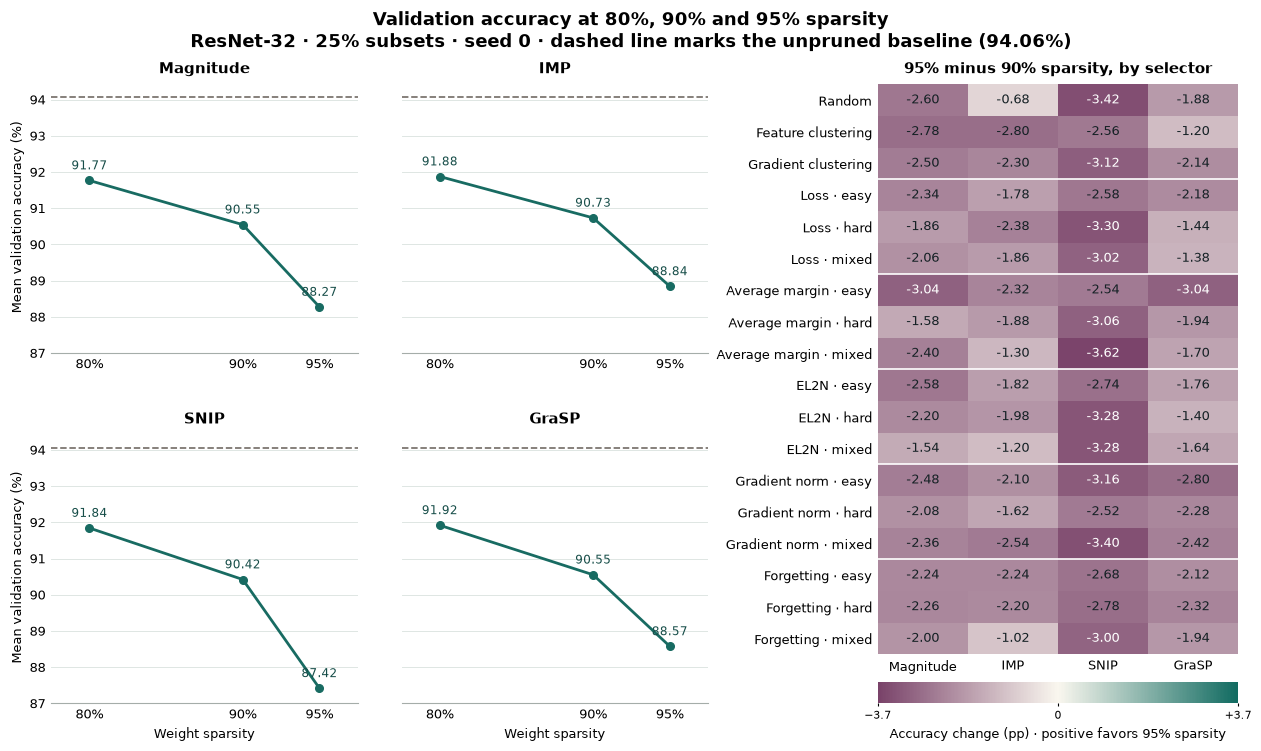

In [33]:
sparsity_levels = [80, 90, 95]
pruner_means = trend_means.loc[methods, sparsity_levels]
gain_95 = (trend_pairs[95] - trend_pairs[90]).unstack("pruning").loc[selector_order, methods]
gain_values = gain_95.to_numpy(dtype=float)
gain_limit = max(.1, np.ceil(np.abs(gain_values).max() * 10) / 10)
gain_colors = LinearSegmentedColormap.from_list("gain_95", ["#794269", "#faf7ef", "#116b61"])
mean_values = pruner_means.to_numpy(dtype=float)
y_low = np.floor((min(mean_values.min(), dense_pct) - .35) * 2) / 2
y_high = np.ceil((max(mean_values.max(), dense_pct) + .35) * 2) / 2

fig = plt.figure(figsize=(12.5, 7.4), layout="constrained")
outer = fig.add_gridspec(1, 2, width_ratios=[1.3, 1], wspace=.09)
trends_grid = outer[0].subgridspec(2, 2, wspace=.07, hspace=.11)
gain_grid = outer[1].subgridspec(2, 1, height_ratios=[28, 1])
fig.suptitle(f"Validation accuracy at 80%, 90% and 95% sparsity\n"
             f"ResNet-32 · 25% subsets · seed 0 · dashed line marks the unpruned baseline ({dense_pct:.2f}%)",
             fontsize=13, weight="bold")

for i, method in enumerate(methods):
    row, col = divmod(i, 2)
    ax = fig.add_subplot(trends_grid[row, col])
    means = pruner_means.loc[method].to_numpy(dtype=float)
    ax.axhline(dense_pct, ls="--", lw=1.25, color="#77716b", zorder=1)
    ax.plot(sparsity_levels, means, marker="o", lw=2, ms=5.5, color="#186b62", zorder=3)
    for level, mean in zip(sparsity_levels, means):
        ax.annotate(f"{mean:.2f}", (level, mean), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=8.5, color="#164d48")
    ax.set_title(method, fontsize=11, weight="bold")
    ax.set_xticks(sparsity_levels, ["80%", "90%", "95%"])
    ax.set_xlim(77.5, 97.5)
    ax.set_ylim(y_low, y_high)
    ax.tick_params(axis="both", labelsize=9, length=0, pad=4)
    ax.tick_params(axis="y", labelleft=col == 0)
    if col == 0:
        ax.set_ylabel("Mean validation accuracy (%)", fontsize=9)
    if row == 1:
        ax.set_xlabel("Weight sparsity", fontsize=9)
    ax.grid(axis="y", color="#dce4e1", lw=.65)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#a5ada9")

ax_gain = fig.add_subplot(gain_grid[0])
gain_image = ax_gain.imshow(gain_values, aspect="auto", interpolation="nearest",
                            vmin=-gain_limit, vmax=gain_limit, cmap=gain_colors)
ax_gain.set_title("95% minus 90% sparsity, by selector", fontsize=11, weight="bold", pad=8)
ax_gain.set_xticks(range(len(methods)), labels=methods)
ax_gain.set_yticks(range(len(selector_order)), labels=selector_order)
ax_gain.tick_params(length=0, pad=4, labelsize=9)
for spine in ax_gain.spines.values():
    spine.set_visible(False)
for boundary in range(3, len(selector_order), 3):
    ax_gain.axhline(boundary - .5, color="white", lw=1.2)
for (row, col), gain in np.ndenumerate(gain_values):
    rgb = np.asarray(gain_image.cmap(gain_image.norm(gain))[:3])
    linear_rgb = np.where(rgb <= .04045, rgb / 12.92, ((rgb + .055) / 1.055) ** 2.4)
    ink = "white" if linear_rgb @ [.2126, .7152, .0722] < .19 else "#152125"
    ax_gain.text(col, row, f"{gain:+.2f}" if abs(gain) >= .005 else "0.00",
                 ha="center", va="center", fontsize=9, color=ink)
gain_bar = fig.colorbar(gain_image, cax=fig.add_subplot(gain_grid[1]), orientation="horizontal")
gain_bar.set_ticks([-gain_limit, 0, gain_limit], labels=[f"−{gain_limit:.1f}", "0", f"+{gain_limit:.1f}"])
gain_bar.set_label("Accuracy change (pp) · positive favors 95% sparsity", fontsize=9)
gain_bar.outline.set_visible(False)
gain_bar.ax.tick_params(labelsize=8, length=2)
plt.show()

### Leading configurations and pruning controls

Each row in the first table follows the same selector and pruner through all three sparsities. Full-data discovery runs and data-free SynFlow appear separately in the second table. The final table gives absolute 95%-sparsity results for all 72 subset-based configurations.

In [34]:
top_rows = []
for level in trend_levels:
    best = trend_counts[level].max()
    for selector, pruner in trend_counts.index[trend_counts[level].eq(best)]:
        scores = trend_pairs.loc[(selector,pruner), trend_levels]
        top_rows.append([f"{level}%", selector, pruner, *scores])
trend_winners = pd.DataFrame(top_rows, columns=["Best at","Selector","Pruner",*trend_levels]).set_index(["Best at","Selector","Pruner"])
display(trend_winners.style.format("{:.2f}%").set_caption("The winning configurations at each sparsity, evaluated at all three levels"))

trend_controls = (trend_frame.loc[trend_frame["fraction"].isna()]
                  .pivot(index=["selector","pruning"], columns="sparsity_pct", values="correct"))
assert set(trend_controls.index) == set(control_rows)
trend_controls = trend_controls.loc[control_rows, trend_levels] * (100 / n_val)
trend_controls.index = [f"Full-data {p}" for p in methods] + ["Data-free SynFlow"]
trend_controls["95 − 90 (pp)"] = trend_controls[95] - trend_controls[90]
display(trend_controls.style.format({**{level:"{:.2f}%" for level in trend_levels},"95 − 90 (pp)":"{:+.2f}"}).set_caption(
    f"Pruning controls on the same validation set · unpruned baseline {dense_pct:.2f}%"))

,,,80,90,95
Best at,Selector,Pruner,,,
80%,Average margin · mixed,GraSP,92.46%,91.04%,89.34%
90%,Average margin · easy,IMP,91.32%,91.22%,88.90%
95%,Random,IMP,91.94%,90.56%,89.88%


sparsity_pct,80,90,95,95 − 90 (pp)
Full-data Magnitude,91.90%,90.70%,88.38%,-2.32
Full-data IMP,92.26%,90.14%,88.48%,-1.66
Full-data SNIP,91.98%,90.24%,87.10%,-3.14
Full-data GraSP,90.82%,90.28%,88.30%,-1.98
Data-free SynFlow,91.80%,90.42%,87.46%,-2.96


In [35]:
absolute95 = trend_pairs[95].unstack("pruning").loc[selector_order, methods]
display(absolute95.style.format("{:.2f}%").highlight_max(axis=0, props="font-weight: bold;")
        .set_caption("95% sparsity · epoch-200 validation accuracy; bold marks each pruner’s highest result"))

pruning,Magnitude,IMP,SNIP,GraSP
selection,,,,
Random,88.04%,89.88%,86.78%,88.88%
Feature clustering,87.82%,88.30%,87.42%,89.06%
Gradient clustering,87.82%,88.72%,87.62%,88.68%
Loss · easy,88.16%,88.68%,87.72%,88.58%
Loss · hard,88.00%,88.78%,87.38%,89.06%
Loss · mixed,88.90%,88.66%,87.16%,88.68%
Average margin · easy,87.76%,88.90%,87.32%,87.52%
Average margin · hard,89.36%,88.70%,87.32%,88.34%
Average margin · mixed,88.14%,89.02%,86.90%,89.34%


**What changed at 95%.** Mean accuracy across the 72 subset runs fell by 1.29 percentage points from 80% to 90% sparsity and a further 2.29 points from 90% to 95%. IMP had the highest 95% mean (88.84%) and the smallest mean decrease from 90% (1.89 points). Random selection with IMP had the highest individual accuracy at 95% (89.88%), 4.18 points below the 94.06% dense baseline. This ranking describes seed 0. The 80% and 95% sweeps ran on an RTX 5080, and the 90% sweep ran on an RTX 5090.

<a id="vgg-resnet-comparison"></a>

## 12. Do ResNet-32’s selector rankings carry over to VGG-19?

Both completed sweeps use CIFAR-10, seed 0, 90% weight sparsity, 25% subsets (11,250 images), and 200 final epochs. Each model was evaluated on the same 5,000 held-out images. We compare the same 18 selector settings and four data-dependent pruners. Each architecture supplies its own reference model for selection and its own dense baseline. [VGG-19 sweep](runs/vgg19-s0-sub25-s90/sweeps/1c40ecfc2c8ddb79f19b/runs.csv) · [ResNet-32 sweep](runs/resnet32-s0-sub25-s90/sweeps/e138bdd3b6e5901d553d/runs.csv)

In [36]:
vgg_root = project / "runs/vgg19-s0-sub25-s90"
vgg_report = vgg_root / "sweeps/1c40ecfc2c8ddb79f19b"
vgg_frame = pd.read_csv(vgg_report / "runs.csv")
vgg_execution = json.loads((vgg_report / "execution.json").read_text(encoding="utf-8"))
assert len(vgg_frame) == vgg_frame["run"].nunique() == len(vgg_execution["runs"]) == 77
assert set(vgg_frame["run"]) == {r["run"] for r in vgg_execution["runs"]}
assert vgg_frame["architecture"].eq("vgg19").all() and vgg_frame["seed"].eq(0).all()
assert vgg_frame["target_sparsity"].eq(.9).all() and vgg_frame["final_epochs"].eq(200).all()
assert vgg_frame["partition"].eq("validation").all() and vgg_frame["fraction"].dropna().eq(.25).all()
assert json.loads((vgg_root / "splits/cifar10-260.json").read_text(encoding="utf-8")) == sparsity_splits[90]
vgg_frame["correct"] = (n_val * vgg_frame["accuracy"]).round().astype(int)
assert np.allclose(vgg_frame["correct"], n_val * vgg_frame["accuracy"])
vgg_frame["selection"] = vgg_frame["selector"].map(names)
scored_vgg = vgg_frame["difficulty"].notna()
vgg_frame.loc[scored_vgg,"selection"] += " · " + vgg_frame.loc[scored_vgg,"difficulty"]
vgg_frame["pruning"] = vgg_frame["pruner"].map({**pruners, "synflow":"SynFlow"})
vgg_subset = vgg_frame.loc[vgg_frame["fraction"].notna()].set_index(["selection","pruning"])
assert vgg_subset.index.is_unique and set(vgg_subset.index) == set(sparsity_order)
arch_counts = pd.DataFrame({"ResNet-32": sparsity_counts[90], "VGG-19": vgg_subset["correct"]}).loc[sparsity_order]
arch_pairs = arch_counts * (100 / n_val)
assert arch_pairs.shape == (72,2) and arch_pairs.notna().all().all()
vgg_dense_path, = (vgg_root / "baselines").glob("*/dense-validation.json")
vgg_dense_record = json.loads(vgg_dense_path.read_text(encoding="utf-8"))
arch_dense = {"ResNet-32": dense_pct, "VGG-19": vgg_dense_record["metrics"]["accuracy"] * 100}

# Inspect masks for a matched configuration to compare the number of eligible weights.
res90 = sparsity_frame.loc[sparsity_frame["sparsity_pct"].eq(90)]
survivors = {}
for arch, root, frame in [("ResNet-32", sweep_dirs[25].parents[1], res90), ("VGG-19", vgg_root, vgg_frame)]:
    record = frame.loc[frame["selector"].eq("random") & frame["pruner"].eq("imp")].iloc[0]
    final = json.loads((root / "final" / record["run"] / "validation.json").read_text(encoding="utf-8"))
    mask = json.loads((root / "masks" / final["mask"] / "summary.json").read_text(encoding="utf-8"))
    survivors[arch] = mask["surviving"]
print(f"Surviving eligible weights: ResNet-32 {survivors['ResNet-32']:,}; VGG-19 {survivors['VGG-19']:,}.")
arch_mean_table = arch_pairs.groupby(level="pruning").mean().loc[methods]
arch_mean_table.loc["All 72 subset configurations"] = arch_pairs.mean()
arch_mean_table["VGG minus ResNet (pp)"] = arch_mean_table["VGG-19"] - arch_mean_table["ResNet-32"]
display(arch_mean_table.style.format({"ResNet-32":"{:.2f}%","VGG-19":"{:.2f}%","VGG minus ResNet (pp)":"{:+.2f}"}))

Surviving eligible weights: ResNet-32 46,187; VGG-19 2,002,400.


,ResNet-32,VGG-19,VGG minus ResNet (pp)
pruning,,,
Magnitude,90.55%,94.04%,+3.49
IMP,90.73%,93.23%,+2.50
SNIP,90.42%,94.06%,+3.64
GraSP,90.55%,93.62%,+3.07
All 72 subset configurations,90.56%,93.74%,+3.17


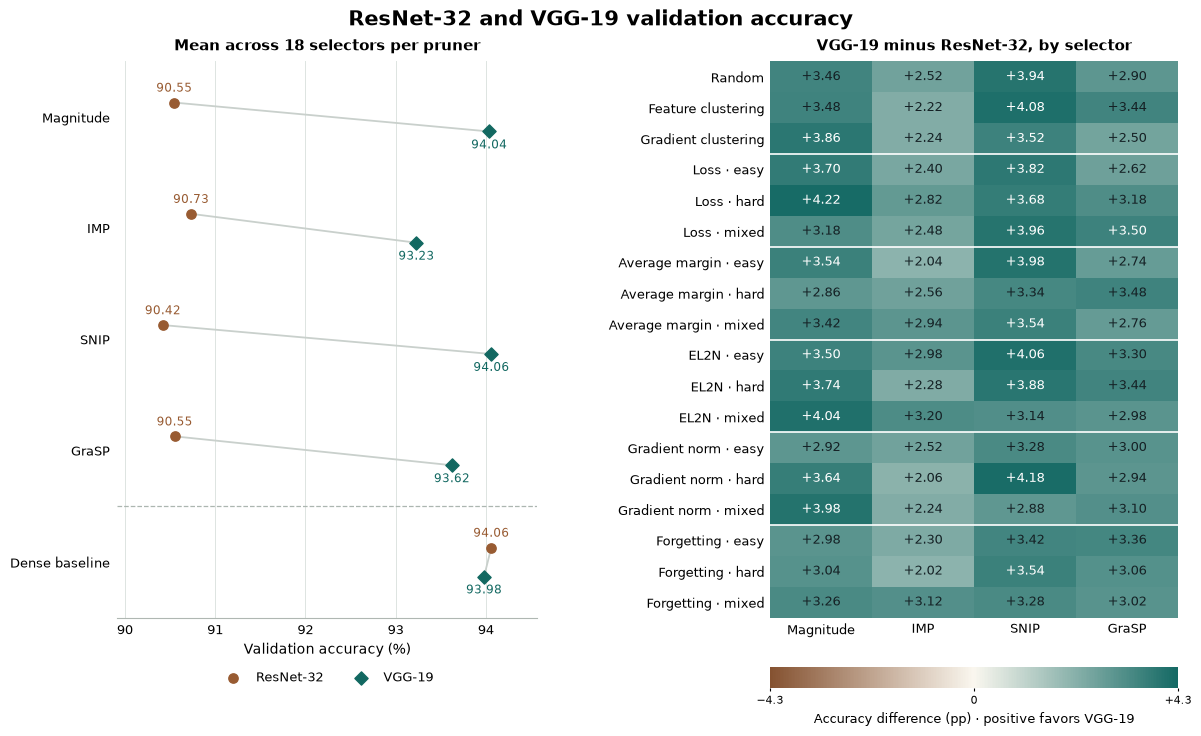

In [37]:
architectures = ["ResNet-32", "VGG-19"]
arch_means = arch_pairs[architectures].groupby(level="pruning").mean().loc[methods].copy()
arch_means.loc["Dense baseline"] = [arch_dense[name] for name in architectures]
arch_delta = (arch_pairs["VGG-19"] - arch_pairs["ResNet-32"]).unstack("pruning").loc[selector_order, methods]
delta_values = arch_delta.to_numpy(dtype=float)
delta_limit = max(.1, np.ceil(np.abs(delta_values).max() * 10) / 10)
delta_cmap = LinearSegmentedColormap.from_list("architecture_difference", ["#855231", "#faf7ef", "#146964"])

fig = plt.figure(figsize=(11.9, 7.25), layout="constrained")
grid = fig.add_gridspec(2, 2, width_ratios=[1.03, 1], height_ratios=[27, 1], wspace=.12)
fig.suptitle("ResNet-32 and VGG-19 validation accuracy", fontsize=15, weight="bold")
ax_mean = fig.add_subplot(grid[0, 0])
arch_rows = np.arange(len(arch_means))
arch_styles = [("#985b32", "o", -.13), ("#126861", "D", .13)]
for row, (resnet, vgg) in enumerate(arch_means.to_numpy()):
    ax_mean.plot([resnet, vgg], [row - .13, row + .13], color="#c9d0cc", lw=1.3, zorder=1)
for name, (color, marker, offset) in zip(architectures, arch_styles):
    values = arch_means[name].to_numpy()
    ax_mean.scatter(values, arch_rows + offset, color=color, marker=marker, s=45, label=name, zorder=3)
    for y, value in zip(arch_rows + offset, values):
        ax_mean.annotate(f"{value:.2f}", (value, y), ha="center", va="center",
                         xytext=(0, 10 if offset < 0 else -10), textcoords="offset points",
                         fontsize=8.5, color=color)
ax_mean.axhline(len(methods) - .5, color="#acb6b0", lw=.9, ls="--")
ax_mean.set_yticks(arch_rows, labels=arch_means.index)
ax_mean.set_ylim(len(arch_means) - .5, -.5)
ax_mean.margins(x=.14)
ax_mean.set_title("Mean across 18 selectors per pruner", fontsize=11, weight="bold", pad=8)
ax_mean.set_xlabel("Validation accuracy (%)")
ax_mean.grid(axis="x", color="#dde4e1", lw=.7)
ax_mean.set_axisbelow(True)
ax_mean.tick_params(length=0, pad=5, labelsize=9)
ax_mean.spines[["top", "right", "left"]].set_visible(False)
ax_mean.spines["bottom"].set_color("#afb7b2")
key_ax = fig.add_subplot(grid[1, 0])
key_ax.axis("off")
key_ax.legend(*ax_mean.get_legend_handles_labels(), loc="center", ncol=2, frameon=False, fontsize=9)

ax_delta = fig.add_subplot(grid[0, 1])
arch_image = ax_delta.imshow(delta_values, aspect="auto", interpolation="nearest",
                             cmap=delta_cmap, vmin=-delta_limit, vmax=delta_limit)
ax_delta.set_title("VGG-19 minus ResNet-32, by selector", fontsize=11, weight="bold", pad=8)
ax_delta.set_xticks(range(len(methods)), labels=methods)
ax_delta.set_yticks(range(len(selector_order)), labels=selector_order)
ax_delta.tick_params(length=0, pad=4, labelsize=9)
for spine in ax_delta.spines.values():
    spine.set_visible(False)
for boundary in range(3, len(selector_order), 3):
    ax_delta.axhline(boundary - .5, color="white", lw=1.2)
for (row, col), value in np.ndenumerate(delta_values):
    rgb = np.asarray(arch_image.cmap(arch_image.norm(value))[:3])
    linear = np.where(rgb <= .04045, rgb / 12.92, ((rgb + .055) / 1.055) ** 2.4)
    ink = "white" if linear @ [.2126, .7152, .0722] < .19 else "#152125"
    ax_delta.text(col, row, f"{value:+.2f}" if abs(value) >= .005 else "0.00",
                  fontsize=9, color=ink, ha="center", va="center")
arch_bar = fig.colorbar(arch_image, cax=fig.add_subplot(grid[1, 1]), orientation="horizontal")
arch_bar.set_ticks([-delta_limit, 0, delta_limit], labels=[f"−{delta_limit:.1f}", "0", f"+{delta_limit:.1f}"])
arch_bar.set_label("Accuracy difference (pp) · positive favors VGG-19", fontsize=9)
arch_bar.ax.tick_params(labelsize=8, length=2)
arch_bar.outline.set_visible(False)
plt.show()

### Which selectors work best for each architecture?

The table ranks all 18 selectors separately within each pruner. Spearman rank correlation compares the two orderings, using average ranks for ties. A value near zero indicates little agreement in these seed-0 rankings. The hit counts in the next table check whether the matching selectors actually chose the same image IDs.

In [38]:
arch_rank_rows = []
for pruner in methods:
    pairs = arch_counts.xs(pruner, level="pruning")
    rank_corr = pairs.rank().corr().loc["ResNet-32", "VGG-19"]
    winners = [", ".join(pairs.index[pairs[a].eq(pairs[a].max())]) for a in ("ResNet-32","VGG-19")]
    arch_rank_rows.append((pruner, winners[0], pairs["ResNet-32"].max() / 50, winners[1], pairs["VGG-19"].max() / 50, rank_corr))
arch_ranks = pd.DataFrame(arch_rank_rows, columns=[
    "Pruner","Best ResNet-32 selector","ResNet-32 accuracy","Best VGG-19 selector","VGG-19 accuracy","Rank correlation"
]).set_index("Pruner")
display(arch_ranks.style.format({"ResNet-32 accuracy":"{:.2f}%", "VGG-19 accuracy":"{:.2f}%", "Rank correlation":"{:+.2f}"}))
cross_arch_membership = {}
for selector, row in vgg_subset.xs("IMP", level="pruning").iterrows():
    record = json.loads((vgg_root / "final" / row["run"] / "validation.json").read_text(encoding="utf-8"))
    artifact = json.loads((vgg_root / "subsets" / record["pruning"]["subset"] / "subset.json").read_text(encoding="utf-8"))
    vgg_ids = set(artifact["ids"])
    assert len(vgg_ids) == 11250
    cross_arch_membership[selector] = len(sparsity_sets[90][selector] & vgg_ids)
cross_arch_membership = pd.Series(cross_arch_membership, name="Shared images").reindex(selector_order)
membership_table = cross_arch_membership.to_frame()
membership_table["Overlap"] = cross_arch_membership / 11250
display(membership_table.style.format({"Shared images":"{:,}", "Overlap":"{:.1%}"}))

,Best ResNet-32 selector,ResNet-32 accuracy,Best VGG-19 selector,VGG-19 accuracy,Rank correlation
Pruner,,,,,
Magnitude,Loss · mixed,90.96%,Gradient norm · mixed,94.38%,-0.33
IMP,Average margin · easy,91.22%,Loss · hard,93.98%,+0.21
SNIP,Gradient norm · mixed,91.08%,EL2N · hard,94.44%,+0.10
GraSP,Average margin · mixed,91.04%,Forgetting · easy,93.88%,+0.13


,Shared images,Overlap
Random,"11,250",100.0%
Feature clustering,"3,899",34.7%
Gradient clustering,"3,673",32.6%
Loss · easy,"6,768",60.2%
Loss · hard,"6,711",59.7%
Loss · mixed,"5,489",48.8%
Average margin · easy,"7,746",68.9%
Average margin · hard,"8,119",72.2%
Average margin · mixed,"6,820",60.6%
EL2N · easy,"6,723",59.8%


### Dense and full-data controls

In [39]:
arch_controls = pd.DataFrame(index=["Dense baseline", *[f"Full-data {p}" for p in methods], "Data-free SynFlow"])
for arch, frame in [("ResNet-32", res90), ("VGG-19", vgg_frame)]:
    controls = frame.loc[frame["fraction"].isna()].set_index(["selector","pruning"])
    assert set(controls.index) == set(control_rows)
    arch_controls[arch] = [arch_dense[arch], *(controls.loc[control_rows, "correct"] * (100 / n_val))]
display(arch_controls.style.format("{:.2f}%"))
display(arch_pairs["VGG-19"].unstack("pruning").loc[selector_order,methods].style.format("{:.2f}%")
        .set_caption("All 72 VGG-19 subset configurations · epoch-200 validation accuracy"))

,ResNet-32,VGG-19
Dense baseline,94.06%,93.98%
Full-data Magnitude,90.70%,94.56%
Full-data IMP,90.14%,94.04%
Full-data SNIP,90.24%,94.02%
Full-data GraSP,90.28%,93.60%
Data-free SynFlow,90.42%,94.00%


pruning,Magnitude,IMP,SNIP,GraSP
selection,,,,
Random,94.10%,93.08%,94.14%,93.66%
Feature clustering,94.08%,93.32%,94.06%,93.70%
Gradient clustering,94.18%,93.26%,94.26%,93.32%
Loss · easy,94.20%,92.86%,94.12%,93.38%
Loss · hard,94.08%,93.98%,94.36%,93.68%
Loss · mixed,94.14%,93.00%,94.14%,93.56%
Average margin · easy,94.34%,93.26%,93.84%,93.30%
Average margin · hard,93.80%,93.14%,93.72%,93.76%
Average margin · mixed,93.96%,93.26%,94.06%,93.80%


At this sparsity, VGG-19 retained about 43 times as many eligible weights as ResNet-32. Their dense baselines were close (93.98% and 94.06%), while VGG-19 scored higher on all 72 matched sparse configurations. The best VGG-19 subset run was hard EL2N with SNIP (94.44%). Full-data magnitude pruning reached 94.56%.

The leading selector changed for every pruner across architectures. Within-pruner rank correlations ranged from −0.33 to +0.21. Random selection reused all 11,250 IDs. The other selectors used architecture-specific reference features or scores. This comparison captures both changes together. Additional seeds would be needed to establish whether the rankings repeat.

<a id="seed-replication"></a>

## 13. Does the same selector win on three training seeds?

The discovery budget here is 11,250 images (25% of the training split). All 216 subset models share the same 90% sparsity target and the same 5,000 validation images. Each seed contributes one result for every selector–pruner pair. Comparing a selector with random **within the same seed and pruner** accounts for differences in how well that seed or pruning method performed. These runs measure variation across training seeds on one fixed split.

In [1]:
%matplotlib inline
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

results_dir = Path.cwd() / "runs"
run_pruners = {"imp": "IMP", "grasp": "GraSP", "magnitude": "Magnitude", "snip": "SNIP", "synflow": "SynFlow"}
run_selectors = {"random": "Random", "feature_cluster": "Feature clustering", "gradient_cluster": "Gradient clustering",
                 "loss": "Loss", "average_margin": "Average margin", "el2n": "EL2N",
                 "gradient_norm": "Gradient norm", "forgetting": "Forgetting"}
data_pruners = ["IMP", "GraSP", "Magnitude", "SNIP"]
selector_labels = [label if key in ("random", "feature_cluster", "gradient_cluster") else f"{label} · {mode}"
                   for key, label in run_selectors.items()
                   for mode in ([""] if key in ("random", "feature_cluster", "gradient_cluster") else ["easy", "hard", "mixed"])]
comparison_keys = [(0, 80), (0, 90), (0, 95), (0, 98), (1, 90), (2, 90)]
frames_by_run, dense_by_run, split_by_run, sweep_roots = {}, {}, {}, {}
for seed, level in comparison_keys:
    root = results_dir / f"resnet32-s{seed}-sub25-s{level}"
    reports = []
    for path in sorted((root / "sweeps").glob("*/config.json")):
        cfg = json.loads(path.read_text(encoding="utf-8"))
        if (cfg["architectures"] == ["resnet32"] and cfg["seeds"] == [seed] and
                cfg["sparsities"] == [level / 100] and cfg["fractions"] == [.25] and
                cfg["final_epochs"] == 200 and cfg["split_seed"] == 260 and not cfg["evaluate_test"]):
            reports.append(path.parent)
    if len(reports) != 1:
        raise ValueError(f"{root}: expected one matching sweep, found {len(reports)}")
    report, = reports
    records = pd.read_csv(report / "runs.csv")
    completed = json.loads((report / "execution.json").read_text(encoding="utf-8"))["runs"]
    assert len(records) == records.run.nunique() == len(completed) == 77
    assert set(records.run) == {event["run"] for event in completed}
    assert records.architecture.eq("resnet32").all() and records.seed.eq(seed).all()
    assert records.partition.eq("validation").all() and records.final_epochs.eq(200).all()
    assert records.target_sparsity.eq(level / 100).all() and records.fraction.dropna().eq(.25).all()
    records["pruning"] = records.pruner.map(run_pruners)
    records["selection"] = records.selector.map({**run_selectors, "full": "Full data", "data-free": "Data free"})
    with_difficulty = records.difficulty.notna()
    records.loc[with_difficulty, "selection"] += " · " + records.loc[with_difficulty, "difficulty"]
    expected = {(s, p) for s in selector_labels for p in data_pruners}
    assert set(zip(records.loc[records.fraction.notna(), "selection"],
                   records.loc[records.fraction.notna(), "pruning"])) == expected
    controls = records.loc[records.fraction.isna()]
    assert set(zip(controls.selection, controls.pruning)) == {("Full data", p) for p in data_pruners} | {("Data free", "SynFlow")}
    split = json.loads((root / "splits/cifar10-260.json").read_text(encoding="utf-8"))
    n_val = len(split["val"])
    assert n_val == 5000 and len(split["train"]) == 45000
    records["correct"] = (records.accuracy * n_val).round().astype(int)
    assert np.allclose(records.correct, records.accuracy * n_val)
    baseline_file, = (root / "baselines").glob(f"resnet32-s{seed}-*/dense-validation.json")
    baseline_record = json.loads(baseline_file.read_text(encoding="utf-8"))
    assert baseline_record["recipe"]["seed"] == seed
    dense_by_run[seed, level] = baseline_record["metrics"]["accuracy"] * 100
    split_by_run[seed, level] = split
    sweep_roots[seed, level] = root
    frames_by_run[seed, level] = records.assign(level=level)
assert all(split == split_by_run[0, 90] for split in split_by_run.values())
combined_reports = pd.concat(frames_by_run.values(), ignore_index=True)
subset_records = combined_reports.loc[combined_reports.fraction.notna()]
records90 = subset_records.loc[subset_records.level.eq(90)]
counts90 = records90.pivot(index=["selection", "pruning"], columns="seed", values="correct")
assert counts90.shape == (72, 3) and counts90.notna().all().all()
points_per_image = 100 / n_val
pct90 = counts90 * points_per_image
random90 = counts90.loc["Random"]
delta90 = counts90.sub(random90, level="pruning") * points_per_image

In [2]:
seed_labels = {s: f"Seed {s}" for s in range(3)}
pruner_seed = pct90.groupby(level="pruning").mean().loc[data_pruners]
pruner_seed.loc["All 72 subset configurations"] = pct90.mean()
pruner_seed["Mean"] = pruner_seed.mean(axis=1)
display(pruner_seed.rename(columns=seed_labels).style.format("{:.2f}%")
        .set_caption("Mean validation accuracy across 18 selector settings per pruner"))

reference_rows = {}
for seed in range(3):
    sweep = frames_by_run[seed, 90]
    ref = sweep.loc[sweep.fraction.isna()].set_index("pruning")
    reference_rows[f"Seed {seed}"] = {"Dense baseline": dense_by_run[seed, 90],
                                      **{f"Full-data {m}": ref.at[m, "correct"] * points_per_image for m in data_pruners},
                                      "Data-free SynFlow": ref.at["SynFlow", "correct"] * points_per_image}
controls90 = pd.DataFrame(reference_rows)
controls90["Mean"] = controls90.mean(axis=1)
# The full-data magnitude control used two procedures. Show its individual seeds only.
controls90.loc["Full-data Magnitude", "Mean"] = np.nan
display(controls90.style.format("{:.2f}%", na_rep="—")
        .set_caption("Reference accuracies on the same validation images"))

seed,Seed 0,Seed 1,Seed 2,Mean
pruning,,,,
IMP,90.73%,90.79%,90.75%,90.76%
GraSP,90.55%,90.65%,90.35%,90.52%
Magnitude,90.55%,90.26%,90.32%,90.38%
SNIP,90.42%,90.32%,90.26%,90.33%
All 72 subset configurations,90.56%,90.51%,90.42%,90.50%


,Seed 0,Seed 1,Seed 2,Mean
Dense baseline,94.06%,93.88%,94.08%,94.01%
Full-data IMP,90.14%,90.24%,90.74%,90.37%
Full-data GraSP,90.28%,90.72%,90.90%,90.63%
Full-data Magnitude,90.70%,90.60%,90.86%,—
Full-data SNIP,90.24%,90.64%,90.22%,90.37%
Data-free SynFlow,90.42%,90.68%,90.44%,90.51%


The full-data magnitude mask at seed 0 came from a separate 70,400-update discovery run. Seeds 1 and 2 used their saved epoch-200 dense checkpoints. The table leaves the pooled cell blank for that control. All 72 subset configurations per seed used the same respective procedures across seeds.

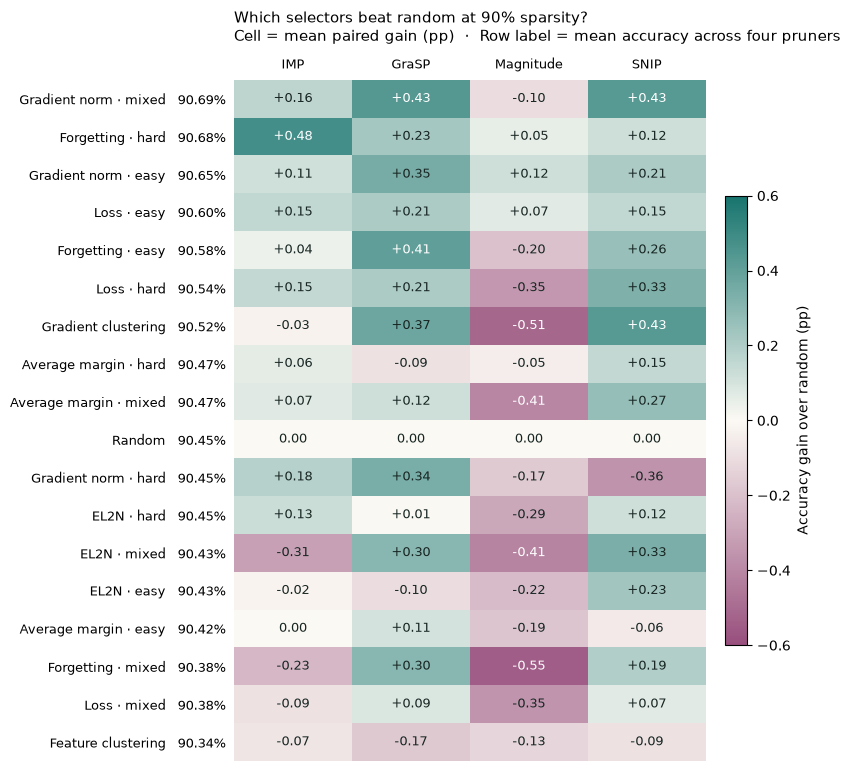

In [3]:
mean_gain = delta90.mean(axis=1).unstack("pruning")[data_pruners]
selector_means = pct90.groupby(level="selection").mean().mean(axis=1)
mean_gain = mean_gain.loc[selector_means.sort_values(ascending=False).index]
heat_colors = LinearSegmentedColormap.from_list("paired_selection_gain", ["#984f7d", "#fcfaf4", "#17746e"])
scale_max = np.ceil(np.abs(mean_gain.to_numpy()).max() * 10) / 10
fig, ax = plt.subplots(figsize=(8.1, 7.6), layout="constrained")
image = ax.imshow(mean_gain, cmap=heat_colors, vmin=-scale_max, vmax=scale_max, aspect="auto")
ax.set_xticks(range(len(data_pruners)), labels=data_pruners)
ax.xaxis.tick_top()
ax.set_yticks(range(len(mean_gain)), labels=[f"{s}   {selector_means[s]:.2f}%" for s in mean_gain.index])
ax.tick_params(length=0, labelsize=9, pad=6)
ax.set_title("Which selectors beat random at 90% sparsity?\n"
             "Cell = mean paired gain (pp)  ·  Row label = mean accuracy across four pruners",
             fontsize=11, loc="left", pad=12)
for (i, j), value in np.ndenumerate(mean_gain.to_numpy()):
    ax.text(j, i, f"{value:+.2f}" if abs(value) > .0001 else "0.00",
            ha="center", va="center", fontsize=9,
            color="white" if abs(value) > .65 * scale_max else "#182623")
for spine in ax.spines.values():
    spine.set_visible(False)
bar = fig.colorbar(image, ax=ax, shrink=.66, pad=.04)
bar.set_label("Accuracy gain over random (pp)")
plt.show()

In [4]:
top_count = counts90.sum(axis=1)
top_per_pruner = top_count.eq(top_count.groupby(level="pruning").transform("max"))
leaders = pct90.loc[top_per_pruner].copy()
leaders["Mean"] = leaders.mean(axis=1)
leaders["Seed SD (pp)"] = pct90.loc[leaders.index].std(axis=1, ddof=1)
leaders["Δ random (pp)"] = delta90.loc[leaders.index].mean(axis=1)
leaders["W / T / L vs random"] = [f"{(g > 0).sum()} / {(g == 0).sum()} / {(g < 0).sum()}"
                                   for _, g in delta90.loc[leaders.index].iterrows()]
leaders = leaders.sort_values("Mean", ascending=False).rename(columns=seed_labels)
display(leaders.style.format({**dict.fromkeys([*seed_labels.values(), "Mean"], "{:.2f}%"),
                              "Seed SD (pp)": "{:.2f}", "Δ random (pp)": "{:+.2f}"})
        .set_caption("Highest three-seed mean within each pruner, including ties"))

imp_settings = pct90.xs("IMP", level="pruning").loc[["Forgetting · hard", "Average margin · easy", "Random"]].copy()
imp_settings.loc["Full data"] = [controls90.loc["Full-data IMP", seed_labels[s]] for s in imp_settings.columns]
imp_settings["Mean"] = imp_settings.mean(axis=1)
display(imp_settings.rename(columns=seed_labels).style.format("{:.2f}%")
        .set_caption("IMP accuracy at 90% sparsity on the same three training seeds"))
display(Markdown("**Easy average margin** had the highest seed-0 IMP accuracy (91.22%). On seeds 1 and 2 "
                 "it reached 90.42% and 90.50%, bringing its three-seed mean to **90.71%**, "
                 "exactly tied with random IMP."))

,seed,Seed 0,Seed 1,Seed 2,Mean,Seed SD (pp),Δ random (pp),W / T / L vs random
selection,pruning,,,,,,,
Forgetting · hard,IMP,91.18%,91.06%,91.34%,91.19%,0.14,+0.48,2 / 1 / 0
Gradient norm · mixed,GraSP,90.70%,90.98%,90.66%,90.78%,0.17,+0.43,2 / 0 / 1
Gradient norm · easy,Magnitude,90.92%,90.90%,90.28%,90.70%,0.36,+0.12,2 / 0 / 1
Gradient clustering,SNIP,90.74%,90.54%,90.54%,90.61%,0.12,+0.43,2 / 0 / 1
Gradient norm · mixed,SNIP,91.08%,90.50%,90.24%,90.61%,0.43,+0.43,2 / 0 / 1


seed,Seed 0,Seed 1,Seed 2,Mean
selection,,,,
Forgetting · hard,91.18%,91.06%,91.34%,91.19%
Average margin · easy,91.22%,90.42%,90.50%,90.71%
Random,90.56%,91.06%,90.52%,90.71%
Full data,90.14%,90.24%,90.74%,90.37%


**Easy average margin** had the highest seed-0 IMP accuracy (91.22%). On seeds 1 and 2 it reached 90.42% and 90.50%, bringing its three-seed mean to **90.71%**, exactly tied with random IMP.

**Hard forgetting with IMP** led the 72 configurations at **91.19%**, compared with **90.71%** for random IMP and **90.37%** for full-data IMP. Its gains over random were **+0.62, 0.00, and +0.82 pp** on seeds 0, 1, and 2. Across four pruners, mixed gradient norm and hard forgetting averaged **90.69%** and **90.68%** respectively. Their unrounded difference was **0.01 pp**. The IMP comparison gives a clearer reason to carry hard forgetting forward than the ranking across pruners. All rankings use validation performance, with three training seeds on one split.

The two leading selector settings across pruners also provide different discovery samples. Mixed gradient norm and hard forgetting shared **2,993**, **3,153**, and **3,200** of 11,250 images at seeds 0, 1, and 2, respectively (27–28%). A new hybrid could use these two selectors under the same 11,250-image budget. The overlap alone cannot tell us its accuracy.

<a id="sparsity-98"></a>

## 14. What happens when only 2% of the weights survive?

This comparison holds the seed at 0, the subset fraction at 25%, and the final training schedule at 200 epochs. Each pruner mean includes the same 18 selector settings. The dense baseline and full-data controls provide references at each sparsity.

level,80% sparse,90% sparse,95% sparse,98% sparse,98 minus 95 (pp)
pruning,,,,,
IMP,91.88%,90.73%,88.84%,84.89%,-3.96
GraSP,91.92%,90.55%,88.57%,83.77%,-4.81
Magnitude,91.77%,90.55%,88.27%,83.16%,-5.11
SNIP,91.84%,90.42%,87.42%,81.35%,-6.06
All 72 subset configurations,91.85%,90.56%,88.28%,83.29%,-4.98


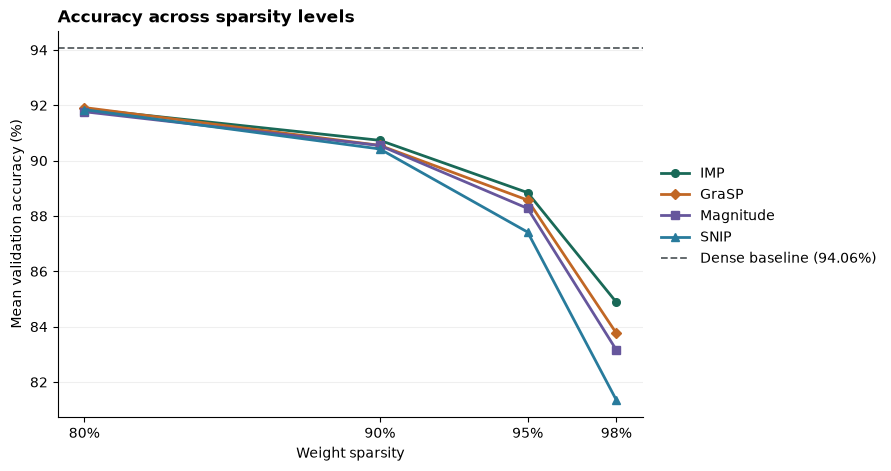

In [5]:
levels = [80, 90, 95, 98]
seed0 = subset_records.loc[subset_records.seed.eq(0)]
counts0 = seed0.pivot(index=["selection", "pruning"], columns="level", values="correct")[levels]
assert counts0.shape == (72, 4) and counts0.notna().all().all()
acc0 = counts0 * points_per_image
pruner_trend = acc0.groupby(level="pruning").mean().loc[data_pruners]
pruner_trend.loc["All 72 subset configurations"] = acc0.mean()
pruner_trend["98 minus 95 (pp)"] = pruner_trend[98] - pruner_trend[95]
display(pruner_trend.rename(columns={lv: f"{lv}% sparse" for lv in levels}).style
        .format({**{f"{lv}% sparse": "{:.2f}%" for lv in levels}, "98 minus 95 (pp)": "{:+.2f}"})
        .set_caption("Seed 0 mean validation accuracy at each sparsity"))

fig, ax = plt.subplots(figsize=(8.8, 4.6), layout="constrained")
styles = {"IMP": ("#196957", "o"), "GraSP": ("#c16725", "D"),
          "Magnitude": ("#66569c", "s"), "SNIP": ("#287b9c", "^")}
for method, (color, marker) in styles.items():
    ax.plot(levels, pruner_trend.loc[method, levels], marker=marker, linewidth=2,
            markersize=5.5, label=method, color=color)
dense0 = dense_by_run[0, 90]
ax.axhline(dense0, linewidth=1.3, linestyle="--", color="#575e61", label=f"Dense baseline ({dense0:.2f}%)")
ax.set(xlabel="Weight sparsity", ylabel="Mean validation accuracy (%)", xticks=levels,
       xticklabels=[f"{level}%" for level in levels])
ax.set_title("Accuracy across sparsity levels", loc="left", fontweight="bold")
ax.grid(axis="y", alpha=.2)
ax.spines[["right", "top"]].set_visible(False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, .52))
plt.show()

In [6]:
controls0 = combined_reports.loc[combined_reports.seed.eq(0) & combined_reports.fraction.isna()]
controls_table = controls0.pivot(index=["selection", "pruning"], columns="level", values="correct")[levels] * points_per_image
display(controls_table.rename(columns={lv: f"{lv}% sparse" for lv in levels}).style.format("{:.2f}%")
        .set_caption("Seed 0 pruning controls at all four sparsities"))
top98 = acc0.loc[acc0[98].eq(acc0[98].groupby(level="pruning").transform("max")), [95, 98]].copy()
top98["Random at 98%"] = top98.index.get_level_values("pruning").map(acc0.loc["Random", 98])
top98["Δ random at 98% (pp)"] = top98[98] - top98["Random at 98%"]
display(top98.sort_values(98, ascending=False).rename(columns={95:"95% sparse", 98:"98% sparse"}).style
        .format({"95% sparse":"{:.2f}%", "98% sparse":"{:.2f}%", "Random at 98%":"{:.2f}%",
                 "Δ random at 98% (pp)":"{:+.2f}"})
        .set_caption("Highest accuracy at 98% sparsity within each pruner"))

,level,95% sparse,98% sparse,Random at 98%,Δ random at 98% (pp)
selection,pruning,,,,
Loss · mixed,IMP,88.66%,85.42%,85.04%,+0.38
Feature clustering,Magnitude,87.82%,84.26%,82.88%,+1.38
Gradient norm · mixed,GraSP,88.28%,84.12%,83.46%,+0.66
EL2N · easy,SNIP,87.24%,81.96%,81.42%,+0.54


In [7]:
# Check actual discovery memberships separately because clusters and near-tied scores can move.
memberships = {}
for lv in [90, 95, 98]:
    root = sweep_roots[0, lv]
    for row in seed0.loc[seed0.level.eq(lv) & seed0.pruner.eq("imp")].itertuples():
        final = json.loads((root / "final" / row.run / "validation.json").read_text(encoding="utf-8"))
        subset_id = final["pruning"]["subset"]
        subset_path = root / "subsets" / subset_id / "subset.json"
        ids = set(json.loads(subset_path.read_text(encoding="utf-8"))["ids"])
        assert len(ids) == 11250
        memberships[lv, row.selection] = ids
same = [s for s in selector_labels if memberships[95, s] == memberships[98, s]]
changed = counts0[98] - counts0[95]
exact_delta = changed.loc[changed.index.get_level_values("selection").isin(same)].mean() * points_per_image
display(Markdown(f"**{(changed < 0).sum()} of {len(changed)} configurations declined** from 95% to 98% sparsity. "
                 f"Across the {len(same) * 4} configurations whose selectors reused exactly the same images, "
                 f"mean accuracy changed by **{exact_delta:+.2f} pp**. "
                 f"The other {18 - len(same)} selectors differed by up to "
                 f"{max(len(memberships[95, s] - memberships[98, s]) for s in selector_labels)} of 11,250 images."))
cluster_overlap = {s: len(memberships[90, s] & memberships[98, s])
                   for s in ["Feature clustering", "Gradient clustering"]}
display(Markdown(f"At 90% versus 98% sparsity, **feature clustering** shared "
                 f"**{cluster_overlap['Feature clustering']:,} / 11,250** images and "
                 f"**gradient clustering** shared **{cluster_overlap['Gradient clustering']:,} / 11,250**."))

**72 of 72 configurations declined** from 95% to 98% sparsity. Across the 28 configurations whose selectors reused exactly the same images, mean accuracy changed by **-5.11 pp**. The other 11 selectors differed by up to 220 of 11,250 images.

At 90% versus 98% sparsity, **feature clustering** shared **11,098 / 11,250** images and **gradient clustering** shared **11,000 / 11,250**.

At 98% sparsity, **IMP averaged 84.89%** and **SNIP averaged 81.35%**. Mixed loss with IMP achieved the highest individual accuracy (**85.42%**). Random IMP scored **85.04%** and full-data IMP scored **83.78%**. The best 90% selector across three seeds and the highest-scoring selector at 98% on seed 0 were different. Replication at 98% would be needed to determine whether that ranking repeats.